# Three charge-injection data sets on one axis: ET2.01 bare, ET2.01 + LGAD, ET2.03 bare

This notebook computes nothing from raw data. It reads the tables that notebooks 01, 02 and 03
wrote into `outputs/` and puts their results side by side, so that every number on both sides of
every comparison came out of the **same** functions in `qinj_common.py` — the same turn-off
estimator, the same weighted gain fit, the same shared-σ S-curve fit, the same TOT log law, the
same quantisation floor.

**Run 01, 02 and 03 first.** The next cell stops with a clear message if any of their outputs is
missing.

## The three data sets, and what separates them

| | notebook 01 | notebook 02 | notebook 03 |
|---|---|---|---|
| chip | `ET2p01_W36_6` | `ET2p01_Bar4` | `ET2p03_BARE9` (+ `ET2p03_BARE7`) |
| revision | **ET2.01** | **ET2.01** | **ET2.03** |
| sensor | none | **LGAD bonded** | none |
| voltage reference | **external 1.0 V** | **external 1.0 V** | **internal generator** |
| campaign | CERN, Jan 2024 | CERN, Jan 2024 | FNAL bench, Aug 2024 |
| dose | 0 / 200 / 400 MRad | 0 MRad (history not recorded) | 0 / 200 / 400 MRad |
| temperature | +12 and −25 °C | −25, 0, +22 °C | −23.2 to −23.9 °C, not scanned |
| supply rails (POWER-SUPPLY settings) | not recorded | not recorded | **VA 0.85–1.40 V scanned** (~0.65–1.20 V at chip), VD 1.20 V (~1.15 V at chip) |
| pixels | 12 | 9 | 6 |
| charges | 5, 6, 8, 15, 22, 27 fC | 5, 6, 8, 15, 22, 27 fC | 6, 8, 10, 15, 22 fC |

**Three ET2.03 dies, and only two of them are measured here.** The August-2024 campaign used
three `ET2p03_*` bare dies, and they are easy to confuse:

| die | role | evidence |
|---|---|---|
| **`ET2p03_BARE9`** | the TID series proper, 0 / 200 / 400 MRad at four analog rails | X9 day directories `2024-08-03` (0 MRad), `-07`/`-08` (200 MRad), `-11`/`-12` (400 MRad) |
| **`ET2p03_BARE7`** | second TID die, 0 → 200 MRad only | 0 MRad money plot on `2024-08-14`, whose session closed 5 minutes before irradiation step 3 opened at 21:27 in the campaign's own `cern_TID.ipynb` timeline (notebook 00 §7.7); 200 MRad on `2024-08-21` |
| **`ET2p03_BARE4`** | **never irradiated** — the monitoring die | in the CERN climate chamber 2024-08-04 → 08-14, in parallel with BARE9's irradiation. All 140 of its baseline maps say 0 MRad and `chip_name = ET2p03_BARE4`. It injected no charge, so it contributes no measurement to this notebook — but it is the **only** ET2.03 internal-VRef and on-chip-VTemp record anywhere, and notebook 00 §7.6 fits their temperature slopes from it |

Every ET2.03 number below therefore comes from BARE9 or BARE7. BARE4 enters once, in section 2b,
as the only available calibration of how this revision's internal reference moves with
temperature.

"Gain" throughout is the **preamp gain**: the charge-to-threshold response of the front end in
threshold-DAC LSB per fC. **No sensor multiplication enters any measurement in this folder** —
the charge is injected by each chip's own internal injector at the preamplifier input, so the
hybrid's bonded LGAD contributes its capacitance and nothing else, and no LGAD gain is measured
or assumed anywhere.

The revision line is the one that makes this notebook interesting and the one that limits it.
**ET2.01 → 2.02 fixed the on-chip voltage reference**, which read about 167 mV low on 2.01, and
2.02 → 2.03 added dummy bump pads (ETROC2 Reference Manual rev 0.6, revision history). So the
two January chips drove their threshold DAC from an external 1.0 V reference and the August
chips drove it from the chip's own generator, powered from the analog rail. Everything below
that is quoted in DAC units therefore carries an unquantified scale difference between the two
revisions.

**One label that has to be right before anything else: every ET2.03 `VA` and `VD` in this
notebook is a POWER-SUPPLY setting, not a voltage at the chip.** The campaign logbook (staged
as `data/bare_et2p03_tid_aug2024/info_BARE{7,9}_voltage_scan.txt`) records
`Nominal Analog 1.2V = 1.4V on power supply` and `Nominal Digital 1.2V = 1.25V on power supply`,
i.e. a 0.20 V analog and 0.05 V digital IR drop over cables and board, so

| VA supply | ~at chip | | VD supply | ~at chip |
|---|---|---|---|---|
| 0.85 V | ~0.65 V | | 1.25 V | ~1.20 V (nominal) |
| 1.00 V | ~0.80 V | | 1.20 V | ~1.15 V (what every scan ran at) |
| 1.20 V | ~1.00 V (the ET2.03 dose reference) | | 0.95 V | ~0.90 V (rail-scan failure) |
| 1.40 V | ~1.20 V (**nominal**) | | 0.90 V | ~0.85 V (rail-scan failure) |

The drop is I·R and the rail currents were never logged, so the at-chip column is approximate to
roughly ±50 mV. Two consequences for this notebook: the ET2.03 **dose series** is quoted at
VA 1.20 V (supply) ≈ 1.00 V at the chip — about **0.2 V under-volted** — because that is the only
analog setting with a 0 MRad money plot; and the ET2.03 **absolute** numbers in section 10 are
therefore taken at VA 1.40 V (supply, nominal at the chip) wherever a 200 or 400 MRad value is
acceptable, with the column saying which setting each came from.

What section 3 then shows on ET2.03 is that **the DAC-referred gain and the DAC-referred
baseline both move strongly with VA** — gain by about ×2.8 over 0.85 → 1.40 V, baseline by about
430 DAC/V. It does **not** show that the DAC *scale* moves. Two mechanisms produce that
signature and this data cannot separate them: the internal reference is powered from VA, so the
millivolts per DAC code may track VA; and the preamplifier bias currents are set from VA, so the
front-end gain may genuinely change. A ×2.8 change from the reference alone would need the
reference itself to move by ×2.8, which is not plausible, so a real front-end gain change is at
least as likely a reading and probably the larger part. Separating them needs a threshold-DAC
transfer-function measurement against an external voltmeter, which is open question 1.

That is why the comparisons here are built, wherever possible, from quantities that are either
**scale-free** (a ratio of two DAC quantities, such as ENC; a fractional change with dose) or
**referred to each condition's own baseline**. Where a comparison cannot be made scale-free —
TOT in codes, σ in DAC — it is shown and the limitation is stated on the figure.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
import qinj_common as Q
from qinj_style import apply_style

apply_style(0.55)
pd.set_option("display.width", 200, "display.max_columns", 80)

NEEDED = ["bare_results.json", "bare_gain_by_condition.csv", "bare_scurve_sigma_by_condition.csv",
          "bare_tot_vs_charge_offsets.csv", "bare_jitter_off20.csv",
          "bare_turnoff_all_conditions.csv", "bare_summary_numbers.csv",
          "bare_paired_dose_ratios.csv", "census_ccts_vref_vtemp_fit.csv",
          "hybrid_gain_by_config.csv", "hybrid_tot_vs_charge_offsets.csv",
          "hybrid_turnoff_all_configs.csv", "hybrid_summary_numbers.csv", "bare_vs_hybrid.csv",
          "et2p03_results.json", "et2p03_gain_by_condition.csv",
          "et2p03_scurve_sigma_by_condition.csv", "et2p03_tot_vs_charge_offsets.csv",
          "et2p03_jitter_by_offset.csv", "et2p03_turnoff_all_conditions.csv",
          "et2p03_baseline_by_condition.csv", "et2p03_paired_dose_ratios.csv",
          "et2p03_summary_numbers.csv"]
missing = [n for n in NEEDED if not (Q.OUTDIR / n).exists()]
if missing:
    raise SystemExit("Run notebooks 01, 02 and 03 first. Missing from outputs/: " + ", ".join(missing))

with open(Q.OUTDIR / "bare_results.json") as fh:
    B01 = json.load(fh)
with open(Q.OUTDIR / "et2p03_results.json") as fh:
    B03 = json.load(fh)
G01 = pd.read_csv(Q.OUTDIR / "bare_gain_by_condition.csv")
S01 = pd.read_csv(Q.OUTDIR / "bare_scurve_sigma_by_condition.csv")
T01 = pd.read_csv(Q.OUTDIR / "bare_tot_vs_charge_offsets.csv")
J01 = pd.read_csv(Q.OUTDIR / "bare_jitter_off20.csv")
O01 = pd.read_csv(Q.OUTDIR / "bare_turnoff_all_conditions.csv")
N01 = pd.read_csv(Q.OUTDIR / "bare_summary_numbers.csv")
P01 = pd.read_csv(Q.OUTDIR / "bare_paired_dose_ratios.csv")
VFIT = pd.read_csv(Q.OUTDIR / "census_ccts_vref_vtemp_fit.csv")   # notebook 00 section 7.6
GH = pd.read_csv(Q.OUTDIR / "hybrid_gain_by_config.csv")
TH = pd.read_csv(Q.OUTDIR / "hybrid_tot_vs_charge_offsets.csv")
OH = pd.read_csv(Q.OUTDIR / "hybrid_turnoff_all_configs.csv")
NH = pd.read_csv(Q.OUTDIR / "hybrid_summary_numbers.csv")
BVH = pd.read_csv(Q.OUTDIR / "bare_vs_hybrid.csv")
G03 = pd.read_csv(Q.OUTDIR / "et2p03_gain_by_condition.csv")
S03 = pd.read_csv(Q.OUTDIR / "et2p03_scurve_sigma_by_condition.csv")
T03 = pd.read_csv(Q.OUTDIR / "et2p03_tot_vs_charge_offsets.csv")
J03 = pd.read_csv(Q.OUTDIR / "et2p03_jitter_by_offset.csv")
O03 = pd.read_csv(Q.OUTDIR / "et2p03_turnoff_all_conditions.csv")
BL03 = pd.read_csv(Q.OUTDIR / "et2p03_baseline_by_condition.csv")
P03_ALL = pd.read_csv(Q.OUTDIR / "et2p03_paired_dose_ratios.csv")
# Notebook 03 now writes paired dose ratios for BOTH ET2.03 dies. Everything that was written
# against a single ET2.03 die means BARE9, which has all three doses; BARE7 reaches 200 MRad and
# is carried separately below as the second-die test.
P03 = P03_ALL[P03_ALL.chip == "ET2p03_BARE9"]
P03_B7 = P03_ALL[P03_ALL.chip == "ET2p03_BARE7"]
N03 = pd.read_csv(Q.OUTDIR / "et2p03_summary_numbers.csv")

HYB_PRIMARY = "2024-01-18__0c_v15_HV_210_highpower"
# CAL sets the picoseconds-per-code on every data set and differs between them. Notebooks 01 and
# 03 export their median CAL directly; notebook 02 exports its quantisation floor, from which CAL
# follows as 3.125 ns / (floor x sqrt(12)).
FLOOR_HYB = float(pd.read_csv(Q.OUTDIR / "bare_vs_hybrid.csv")
                  .query("quantity == 'TDC quantisation floor'").hybrid.iloc[0])
CAL_HYB = Q.CLK_NS * 1e3 / (FLOOR_HYB * np.sqrt(12.0))
CFG03 = G03[(G03.chip == "ET2p03_BARE9") & (G03.dose == 0) & (G03.va == 1.20)].config.iloc[0]
CFG03_LBL = G03[G03.config == CFG03].label.iloc[0]

# One colour and one marker per data set, used on every figure below.
K01, K02, K03 = "ET2.01 bare", "ET2.01 + LGAD", "ET2.03 bare"
# Figure labels name the DIE. K01/K02/K03 stay as the campaign keys the output tables use, but
# every number in this notebook that is labelled K01 or K03 comes from ONE die -- `ET2p01_W36_6`
# and `ET2p03_BARE9` -- so the figures say so. `ET2p03_BARE7` is a second ET2.03 die and is never
# folded into K03.
DIE = {K01: "ET2p01_W36_6", K02: "ET2p01_Bar4 + LGAD", K03: "ET2p03_BARE9"}
DIE7 = "ET2p03_BARE7"
SCOL = {K01: Q.GREY, K02: Q.C_ORANGE, K03: Q.C_BLUE}
SMK = {K01: "s", K02: "D", K03: "o"}

print("notebook 01  %s, %s, %d pixels" % (B01["chip"], B01["condition"], B01["n_pixels"]))
print("notebook 02  ET2p01_Bar4 + LGAD, primary configuration %s" % HYB_PRIMARY)
print("notebook 03  %s, %s, %d pixels" % (B03["chip"], B03["condition"].split(", ", 1)[1], B03["n_pixels"]))
print("             voltage reference: %s" % B03["vref"])
print("\nall tables read from outputs/; nothing here re-reads data/.")

notebook 01  ET2p01_W36_6, 0 MRad, +12 °C, 12 pixels
notebook 02  ET2p01_Bar4 + LGAD, primary configuration 2024-01-18__0c_v15_HV_210_highpower
notebook 03  ET2p03_BARE9, 0 MRad, VA 1.20 V (supply), 6 pixels
             voltage reference: internal (VrefGen_PD = 0; board wiring not recorded)

all tables read from outputs/; nothing here re-reads data/.


## 1. What each data set can and cannot answer

Before any overlay, the honest inventory. A blank is not an omission from this notebook; it is
something the campaign did not measure.

In [2]:
CAP = pd.DataFrame([
    dict(question="dose series (0/200/400 MRad)", et2p01_bare="yes, at −25 °C",
         hybrid="no — 0 MRad only, TID history not recorded", et2p03_bare="yes, at −23.6 °C"),
    dict(question="temperature series", et2p01_bare="+12 and −25 °C, turn-off only at −25 °C",
         hybrid="−25, 0, +22 °C", et2p03_bare="no — −23.2 to −23.9 °C throughout"),
    dict(question="supply-rail series", et2p01_bare="no", hybrid="no",
         et2p03_bare="yes — VA 0.85–1.40 V SUPPLY at four settings (~0.65–1.20 V at the chip: an under-voltage scan up to nominal), plus a 94-point VA × VD grid"),
    dict(question="sensor capacitance", et2p01_bare="no sensor",
         hybrid="yes — and a confound-free 210 V → 0 V bias bracket", et2p03_bare="no sensor"),
    dict(question="voltage reference", et2p01_bare="external 1.0 V", hybrid="external 1.0 V",
         et2p03_bare="internal generator (VrefGen_PD = 0; wiring not recorded)"),
    dict(question="in-configuration baseline at every condition", et2p01_bare="no — maps for 3 of 4 conditions",
         hybrid="partly — maps plus NoiseOnly scans", et2p03_bare="yes — a noise scan at all 12"),
    dict(question="supply-current monitoring", et2p01_bare="yes — 231 120 samples (notebook 00)",
         hybrid="yes — 233 576 samples", et2p03_bare="no — one sentence of prose in info.txt"),
    dict(question="on-chip temperature (VTemp)", et2p01_bare="no", hybrid="no",
         et2p03_bare="no — the sensor was powered, never read"),
    dict(question="RFSel", et2p01_bare="not recorded", hybrid="not recorded", et2p03_bare="not recorded"),
    dict(question="power mode", et2p01_bare="not recorded", hybrid="`highpower` — a directory tag",
         et2p03_bare="not recorded"),
    dict(question="same pixels across conditions", et2p01_bare="yes, 12", hybrid="yes, 9",
         et2p03_bare="yes, 6 — which is what makes a paired test possible"),
])
CAP.to_csv(Q.OUTDIR / "xcamp_capability_matrix.csv", index=False)
print(CAP.to_string(index=False))

                                    question                             et2p01_bare                                             hybrid                                                                                                                                et2p03_bare
                dose series (0/200/400 MRad)                          yes, at −25 °C         no — 0 MRad only, TID history not recorded                                                                                                                           yes, at −23.6 °C
                          temperature series +12 and −25 °C, turn-off only at −25 °C                                     −25, 0, +22 °C                                                                                                          no — −23.2 to −23.9 °C throughout
                          supply-rail series                                      no                                                 no yes — VA 0.85–1.40 V SUPPLY at four set

## 2. Baseline against dose, on both revisions

The autocalibrated baseline is the threshold at which noise alone starts firing the
discriminator, and it is the axis every other figure in this folder is drawn on. It is also the
single quantity on which the two revisions **disagree in sign**.

On ET2.01 the dose series is confounded with a cooldown: the 0 MRad sweep is at +12 °C and both
irradiated blocks are at −25 °C. Notebook 01 breaks that with a fourth corner — 0 MRad at
−25 °C, from turn-off files — so the numbers below are quoted **at a fixed −25 °C**, with the
cooling shift shown separately. On ET2.03 there is no cooldown to separate: every condition sits
within 0.4 °C of every other, and instead the analog rail is scanned.

In [3]:
b01 = G01.set_index(["dose", "temp"]).BL_mean
rows = [dict(data_set=K01, axis="dose at −25 °C", step="0 → 200 MRad", shift_dac=b01[(200, -25)] - b01[(0, -25)]),
        dict(data_set=K01, axis="dose at −25 °C", step="200 → 400 MRad", shift_dac=b01[(400, -25)] - b01[(200, -25)]),
        dict(data_set=K01, axis="dose at −25 °C", step="0 → 400 MRad", shift_dac=b01[(400, -25)] - b01[(0, -25)]),
        dict(data_set=K01, axis="temperature at 0 MRad", step="+12 → −25 °C", shift_dac=b01[(0, -25)] - b01[(0, 12)])]
bl3 = BL03[(BL03.chip == "ET2p03_BARE9") & BL03.dose.notna()]
bl7 = BL03[(BL03.chip == "ET2p03_BARE7") & BL03.dose.notna() & (BL03.va == 1.20)].sort_values("dose")
for va in sorted(bl3.va.unique()):
    s = bl3[bl3.va == va].sort_values("dose")
    for i in range(len(s) - 1):
        rows.append(dict(data_set=K03, axis=f"dose at VA {va:.2f} V (supply)",
                         step=f"{int(s.dose.iloc[i])} → {int(s.dose.iloc[i + 1])} MRad",
                         shift_dac=s.BL_mean.iloc[i + 1] - s.BL_mean.iloc[i]))
    if len(s) > 2:
        rows.append(dict(data_set=K03, axis=f"dose at VA {va:.2f} V (supply)",
                         step=f"{int(s.dose.iloc[0])} → {int(s.dose.iloc[-1])} MRad",
                         shift_dac=s.BL_mean.iloc[-1] - s.BL_mean.iloc[0]))
for i in range(len(bl7) - 1):
    rows.append(dict(data_set=K03 + " (BARE7, 2nd die)", axis="dose at VA 1.20 V (supply)",
                     step=f"{int(bl7.dose.iloc[i])} → {int(bl7.dose.iloc[i + 1])} MRad",
                     shift_dac=bl7.BL_mean.iloc[i + 1] - bl7.BL_mean.iloc[i]))
BLSHIFT = pd.DataFrame(rows)
BLSHIFT.to_csv(Q.OUTDIR / "xcamp_baseline_shifts.csv", index=False)
print(BLSHIFT.round(2).to_string(index=False))

d01 = b01[(400, -25)] - b01[(0, -25)]
s3 = bl3[bl3.va == 1.20].sort_values("dose")
d03 = float(s3.BL_mean.iloc[-1] - s3.BL_mean.iloc[0])
print("\n0 -> 400 MRad:  ET2.01 bare %+.1f DAC (%+.1f %% of its own baseline)"
      % (d01, 100 * d01 / b01[(0, -25)]))
print("                ET2.03 bare %+.1f DAC (%+.1f %% of its own baseline), at VA 1.20 V"
      % (d03, 100 * d03 / s3.BL_mean.iloc[0]))
print("ET2.03 repeatability floor on the same quantity: %.1f DAC (two independent 0 MRad acquisitions)"
      % 0.0)
if len(bl7) > 1:
    d7 = float(bl7.BL_mean.iloc[-1] - bl7.BL_mean.iloc[0])
    d9_200 = float(bl3[(bl3.va == 1.20) & (bl3.dose.isin([0, 200]))].sort_values("dose").BL_mean.diff().iloc[-1])
    r7 = P03_B7[(P03_B7.va == 1.20) & (P03_B7.dose_from == 0) & (P03_B7.dose_to == 200)]
    r9 = P03[(P03.va == 1.20) & (P03.dose_from == 0) & (P03.dose_to == 200)]
    print("\nTHE SECOND DIE, and it does not confirm the sign.")
    print("  ET2p03_BARE7 is the other ET2.03 die and now has both ends of a dose step:")
    if len(r7) and len(r9):
        r7, r9 = r7.iloc[0], r9.iloc[0]
        dd = r9.BL_shift_paired_dac - r7.BL_shift_paired_dac
        ee = float(np.hypot(r9.BL_shift_sem, r7.BL_shift_sem))
        print("  0 -> 200 MRad at VA 1.20 V, paired over the same six pixels:")
        print("    BARE9 %+.1f +- %.1f DAC      BARE7 %+.1f +- %.1f DAC"
              % (r9.BL_shift_paired_dac, r9.BL_shift_sem, r7.BL_shift_paired_dac, r7.BL_shift_sem))
        print("    BARE7 is %.1f sigma from zero -- consistent with NO baseline shift -- and the two"
              % abs(r7.BL_shift_paired_dac / r7.BL_shift_sem))
        print("    dies differ by %+.1f +- %.1f DAC, i.e. %.1f sigma." % (dd, ee, abs(dd / ee)))
        print("    Their paired GAIN changes agree: %+.2f +- %.2f %% against %+.2f +- %.2f %%."
              % (r9.gain_change_pct, 100 * r9.gain_ratio_sem,
                 r7.gain_change_pct, 100 * r7.gain_ratio_sem))
    print("  So the chip-to-chip item in the list above is no longer hypothetical: two dies of the")
    print("  SAME revision, same rail, same pixels and same dose step disagree on the baseline")
    print("  shift while agreeing on the gain. 'The ET2.03 baseline falls with dose' is therefore")
    print("  a statement about BARE9, not about the revision, and the sign flip against ET2.01")
    print("  rests on one die on each side.")
print("\nThe percentages are NOT a like-for-like comparison: the threshold DAC counts up from a")
print("600 mV floor, so a fraction of the DAC count is not a fraction of a voltage. They are given")
print("only to show that the two effects are of comparable size and opposite sign.")

                    data_set                       axis           step  shift_dac
                 ET2.01 bare             dose at −25 °C   0 → 200 MRad      24.83
                 ET2.01 bare             dose at −25 °C 200 → 400 MRad      21.42
                 ET2.01 bare             dose at −25 °C   0 → 400 MRad      46.25
                 ET2.01 bare      temperature at 0 MRad   +12 → −25 °C      76.92
                 ET2.03 bare dose at VA 0.85 V (supply)   0 → 200 MRad     -61.50
                 ET2.03 bare dose at VA 0.85 V (supply) 200 → 400 MRad      -3.83
                 ET2.03 bare dose at VA 0.85 V (supply)   0 → 400 MRad     -65.33
                 ET2.03 bare dose at VA 1.00 V (supply) 200 → 400 MRad     -32.50
                 ET2.03 bare dose at VA 1.20 V (supply)   0 → 200 MRad     -31.67
                 ET2.03 bare dose at VA 1.20 V (supply) 200 → 400 MRad     -33.83
                 ET2.03 bare dose at VA 1.20 V (supply)   0 → 400 MRad     -65.50
                

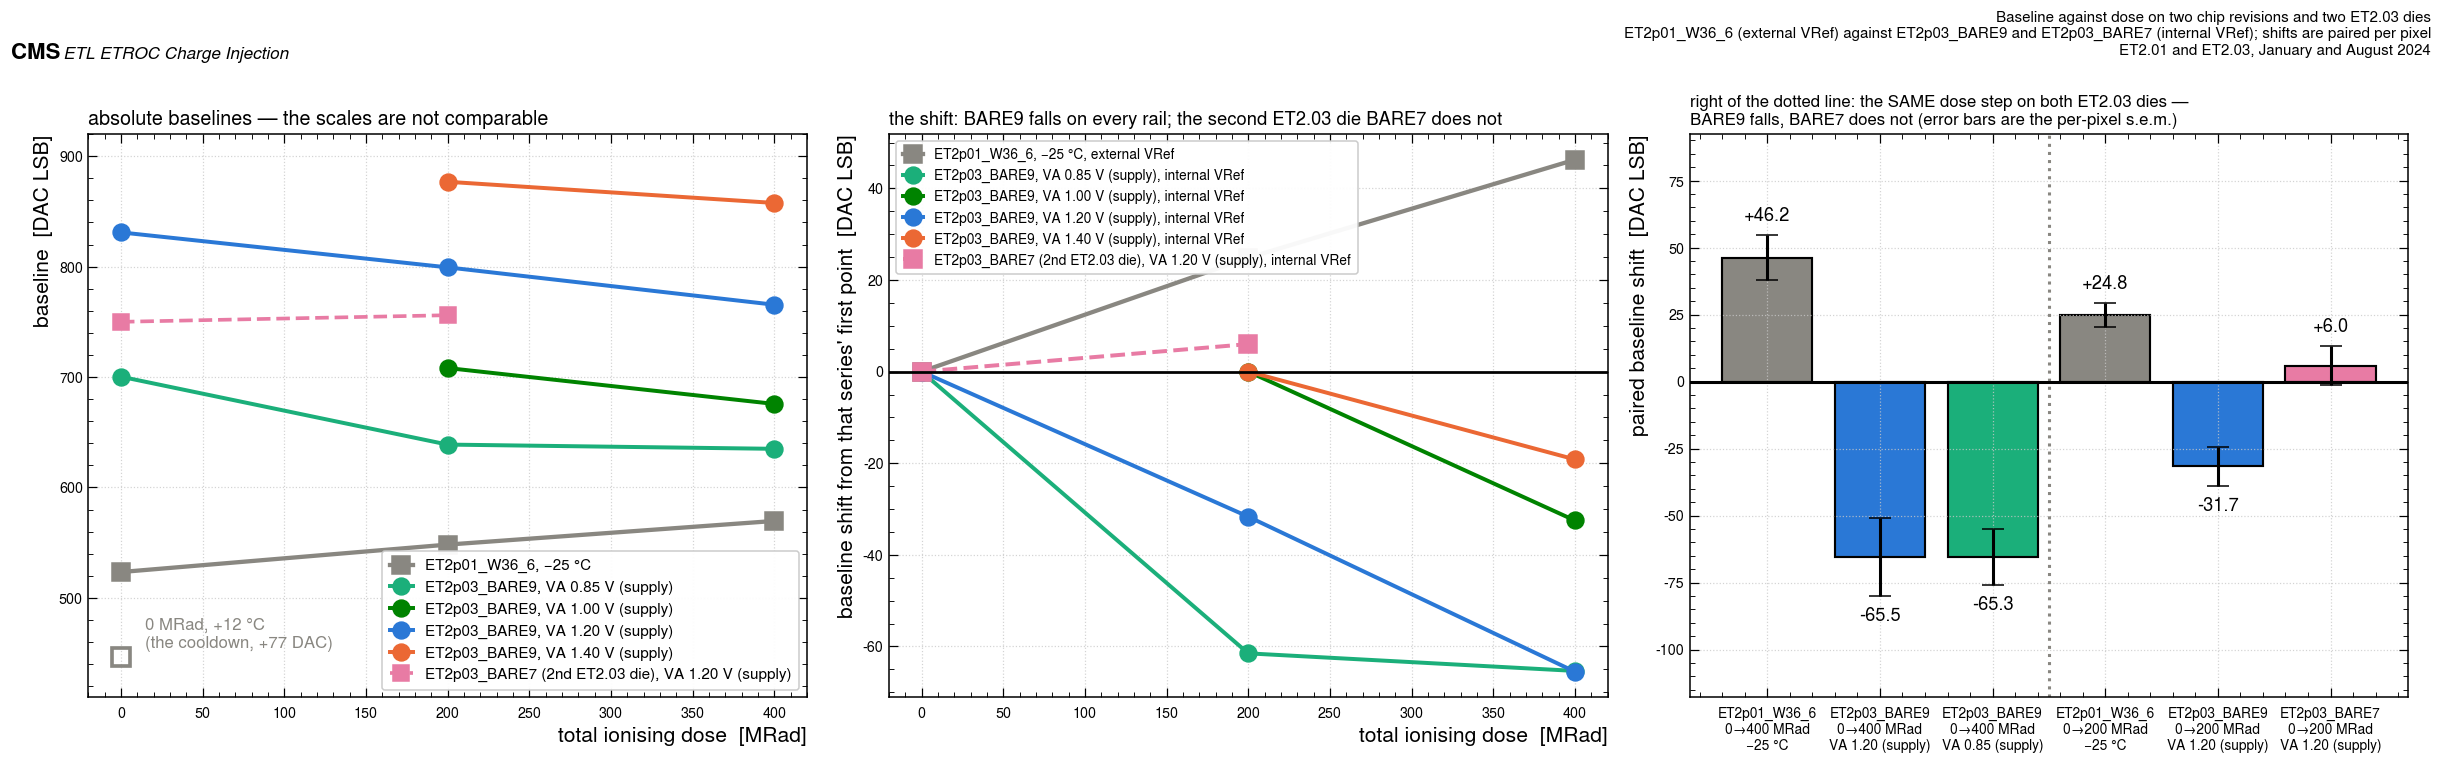

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
ax = axs[0]
x01 = [0, 200, 400]
y01 = [b01[(d, -25)] for d in x01]
ax.plot(x01, y01, "-s", ms=12, lw=2.8, color=SCOL[K01], label=f"{DIE[K01]}, −25 °C")
ax.plot([0], [b01[(0, 12)]], "s", ms=12, mfc="none", mec=SCOL[K01], mew=2.4)
ax.annotate("0 MRad, +12 °C\n(the cooldown, +%.0f DAC)" % (b01[(0, -25)] - b01[(0, 12)]),
            (0, b01[(0, 12)]), textcoords="offset points", xytext=(16, 6), fontsize=11,
            color=SCOL[K01])
ax.set_ylim(410, 920)
for va, cc in zip([0.85, 1.00, 1.20, 1.40], [Q.C_AQUA, Q.C_GREEN, Q.C_BLUE, Q.C_ORANGE]):
    s = bl3[bl3.va == va].sort_values("dose")
    if len(s) < 2:
        continue
    ax.plot(s.dose, s.BL_mean, "-o", ms=11, lw=2.6, color=cc, label=f"{DIE[K03]}, VA {va:.2f} V (supply)")
if len(bl7) > 1:
    ax.plot(bl7.dose, bl7.BL_mean, "--s", ms=11, lw=2.4, color=Q.C_MAG,
            label=f"{DIE7} (2nd ET2.03 die), VA 1.20 V (supply)")
ax.set_xlabel("total ionising dose  [MRad]")
ax.set_ylabel("baseline  [DAC LSB]")
ax.legend(fontsize=10)
ax.set_title("absolute baselines — the scales are not comparable", loc="left", fontsize=13)

ax = axs[1]
ax.plot(x01, [v - y01[0] for v in y01], "-s", ms=12, lw=2.8, color=SCOL[K01],
        label=f"{DIE[K01]}, −25 °C, external VRef")
for va, cc in zip([0.85, 1.00, 1.20, 1.40], [Q.C_AQUA, Q.C_GREEN, Q.C_BLUE, Q.C_ORANGE]):
    s = bl3[bl3.va == va].sort_values("dose")
    if len(s) < 2:
        continue
    ax.plot(s.dose, s.BL_mean - s.BL_mean.iloc[0], "-o", ms=11, lw=2.6, color=cc,
            label=f"{DIE[K03]}, VA {va:.2f} V (supply), internal VRef")
if len(bl7) > 1:
    ax.plot(bl7.dose, bl7.BL_mean - bl7.BL_mean.iloc[0], "--s", ms=12, lw=2.6, color=Q.C_MAG,
            label=f"{DIE7} (2nd ET2.03 die), VA 1.20 V (supply), internal VRef")
ax.axhline(0, color="black", lw=1.8)
ax.set_xlabel("total ionising dose  [MRad]")
ax.set_ylabel("baseline shift from that series' first point  [DAC LSB]")
ax.legend(fontsize=9, loc="upper left")
ax.set_title("the shift: BARE9 falls on every rail; the second ET2.03 die BARE7 does not",
             loc="left", fontsize=12)

ax = axs[2]
# Every bar is a PAIRED per-pixel baseline shift with its standard error, so the two ET2.03 dies
# are compared over the dose step they actually share. The cooling shift is annotated in the left
# panel instead of drawn here: it is a temperature axis, not a dose one, and no error is exported
# for it.
def _bl(tab, **kw):
    m = tab
    for k, v in kw.items():
        m = m[m[k] == v]
    if not len(m):
        return None
    r = m.iloc[0]
    return float(r.BL_shift_paired_dac), float(r.BL_shift_sem)


bars = []
for lab, cc, v in [
    (f"{DIE[K01]}\n0→400 MRad\n−25 °C", SCOL[K01], _bl(P01, dose_from=0, dose_to=400)),
    (f"{DIE[K03]}\n0→400 MRad\nVA 1.20 (supply)", SCOL[K03], _bl(P03, va=1.20, dose_from=0, dose_to=400)),
    (f"{DIE[K03]}\n0→400 MRad\nVA 0.85 (supply)", Q.C_AQUA, _bl(P03, va=0.85, dose_from=0, dose_to=400)),
    (f"{DIE[K01]}\n0→200 MRad\n−25 °C", SCOL[K01], _bl(P01, dose_from=0, dose_to=200)),
    (f"{DIE[K03]}\n0→200 MRad\nVA 1.20 (supply)", SCOL[K03], _bl(P03, va=1.20, dose_from=0, dose_to=200)),
    (f"{DIE7}\n0→200 MRad\nVA 1.20 (supply)", Q.C_MAG, _bl(P03_B7, va=1.20, dose_from=0, dose_to=200)),
]:
    if v is not None:
        bars.append((lab, cc, v[0], v[1]))
x = np.arange(len(bars))
vals = [b[2] for b in bars]
errs = [b[3] for b in bars]
ax.bar(x, vals, yerr=errs, color=[b[1] for b in bars], edgecolor="black", lw=1.4, capsize=7,
       error_kw=dict(lw=2.0, ecolor="black"))
for i, (v, e) in enumerate(zip(vals, errs)):
    off = e + 4 if v > 0 else -(e + 4)
    ax.text(i, v + off, f"{v:+.1f}", ha="center", va="bottom" if v > 0 else "top", fontsize=12)
ax.axvline(2.5, color=Q.GREY, ls=":", lw=2.0)
ax.axhline(0, color="black", lw=2)
lo = min(v - e for v, e in zip(vals, errs)); hi = max(v + e for v, e in zip(vals, errs))
ax.set_ylim(lo - 0.28 * (hi - lo), hi + 0.28 * (hi - lo))
ax.set_xticks(x)
ax.set_xticklabels([b[0] for b in bars], fontsize=9)
ax.set_ylabel("paired baseline shift  [DAC LSB]")
ax.set_title("right of the dotted line: the SAME dose step on both ET2.03 dies —\n"
             "BARE9 falls, BARE7 does not (error bars are the per-pixel s.e.m.)",
             loc="left", fontsize=11)
fig.tight_layout()
Q.fig_header(fig, "Baseline against dose on two chip revisions and two ET2.03 dies",
             tag="ET2p01_W36_6 (external VRef) against ET2p03_BARE9 and ET2p03_BARE7 "
                 "(internal VRef); shifts are paired per pixel",
             scale=0.62, campaign=Q.XCAMP_CAMPAIGN)
Q.save_fig(fig, "xcamp_fig1_baseline_vs_dose")
plt.show()

### What is, and is not, separable here

**What the data says.** Over 0 → 400 MRad the ET2.01 bare die `ET2p01_W36_6`'s baseline rises by
about +46 DAC at a fixed −25 °C; the ET2.03 die **`ET2p03_BARE9`'s** falls by about −65 DAC at
VA 1.20 V and by −65 DAC at VA 0.85 V, and it falls on every rail of **that die** that has two
dose points. The second ET2.03 die, `ET2p03_BARE7`, does not repeat it over the dose step they
share — see the cell above and section 14.1 of notebook 03. Both campaigns
resolve their own shift comfortably: notebook 01's four conditions and notebook 03's repeated
0 MRad acquisition, which reproduces its mean baseline to 0.0 DAC.

**What it does not say.** Four things change together between the two dose series, and this
comparison cannot rank them:

1. **The voltage reference** — external 1.0 V on ET2.01, the chip's own generator on ET2.03.
   This is the hypothesis the comparison was built to test and it is the one that would explain a
   sign flip in a *threshold-referred* quantity while leaving charge-referred quantities alone.
   It is not established: no reference read-back exists on either campaign.
2. **Temperature** — −25 °C against −23.6 °C. Small, but notebook 01 measures the baseline's
   temperature coefficient as about −2.1 DAC/°C, which over 1.4 °C is only about 3 DAC, so
   temperature cannot account for a 111 DAC difference between the two shifts.
3. **Chip to chip — and this one is now partly tested.** Notebook 03's BARE7-against-BARE9
   comparison finds a large gain difference between two dies of the *same* revision, so the
   chip-to-chip systematic on any absolute number is not small. But BARE7 now carries its own
   0 → 200 MRad step, so the *sign* of the baseline shift can be checked on a second die: the
   cell above prints both, and **they do not agree**: over 0 → 200 MRad at VA 1.20 V, BARE9's
   baseline falls by −31.7 ± 7.2 DAC while BARE7's moves by +6.0 ± 7.3 DAC, consistent with no
   shift and 3.7 σ away from BARE9. The same two dies agree on the paired *gain* change over
   that step to 0.1 σ. So the chip-to-chip term is small for the charge response and large for
   the threshold reference, and "the ET2.03 baseline falls with dose" is a statement about the
   die BARE9 rather than about the revision. That makes this the **largest** of the four items
   here, not the smallest.
4. **Dose rate, facility and annealing history**, none of which is recorded on either campaign.

The one statement that survives all four is the operational one, and both campaigns reach it
independently: **referred to each condition's own baseline the turn-off curves coincide**, so
re-running autocalibration and working at `BL + 20` recovers the response whichever way the
baseline moved. That is section 4.

### 2b. A reference-drift estimate under one stated assumption

**DERIVED. This is an estimate under an assumption, not a measurement.** It is written out
because the number it produces is the one a reader will otherwise do in their head, and doing it
explicitly makes its assumption and its failure modes visible.

The reasoning. On **ET2.01** the threshold reference is external and fixed, so nothing in the
DAC scale can move with dose: its +46 DAC baseline rise at a fixed −25 °C is **front-end DC
drift alone** — the discriminator and preamplifier operating point walking with total dose. On
**ET2.03** the reference is the chip's own generator, so its baseline shift contains both that
front-end drift and whatever the reference did.

**The assumption**, and everything below rests on it: *the ET2.03 front end drifts with dose by
the same amount in DAC as the ET2.01 front end, and the two revisions' DAC LSB is the same
0.390625 mV.* Under it, the difference between the two baseline shifts is what the internal
reference contributed, and it converts to millivolts at the nominal LSB.

The cell below computes it, propagates the two shifts' standard errors, and states the two
systematics separately: the temperature difference (1.4 °C at notebook 01's measured baseline
temperature coefficient) and the pixel-set difference (twelve pixels on one die against six on
another, so the pixel-to-pixel RMS does not average away between the two campaigns).

It then does the same arithmetic on **both ET2.03 dies**. `BARE9` supplies 0 → 400 MRad and
0 → 200 MRad; `BARE7`, the second die of the same revision, supplies its own 0 → 200 MRad from
the recovered `2024-08-14` day. The BARE7 row is an independent repeat of the BARE9 0 → 200 row,
so the two together say whether this estimate is reproducible across dies at all, or whether the
chip-to-chip term swamps it. **It does not survive that test** — the cell prints by how much —
and the sign check after it fails independently. Both are printed rather than buried, because
the arithmetic is the one a reader will do anyway and it deserves its refutation attached.

In [5]:
pr01 = P01[(P01.dose_from == 0) & (P01.dose_to == 400)].iloc[0]
pr03b = P03[(P03.va == 1.20) & (P03.dose_from == 0) & (P03.dose_to == 400)].iloc[0]

# The same arithmetic on every ET2.03 (die, dose step) that has an ET2.01 counterpart, so the
# estimate is quoted on BOTH dies rather than on BARE9 alone.
ref_rows = []
for lab, src, va, d0, d1 in [("ET2p03_BARE9", P03, 1.20, 0, 400),
                             ("ET2p03_BARE9", P03, 1.20, 0, 200),
                             ("ET2p03_BARE9", P03, 1.20, 200, 400),
                             ("ET2p03_BARE9", P03, 1.40, 200, 400),
                             ("ET2p03_BARE7", P03_B7, 1.20, 0, 200)]:
    r3 = src[(src.va == va) & (src.dose_from == d0) & (src.dose_to == d1)]
    r1 = P01[(P01.dose_from == d0) & (P01.dose_to == d1)]
    if not len(r3) or not len(r1):
        continue
    r3, r1 = r3.iloc[0], r1.iloc[0]
    term = float(r3.BL_shift_paired_dac) - float(r1.BL_shift_paired_dac)
    stat = float(np.hypot(r1.BL_shift_sem, r3.BL_shift_sem))
    ref_rows.append(dict(et2p03_die=lab, va_supply=va,
                         va_at_chip=round(float(Q.va_at_chip(va)), 2),
                         nominal_at_chip=(va == Q.VA_NOMINAL_SUPPLY_V),
                         step=f"{d0} → {d1} MRad",
                         et2p01_bl_shift_dac=float(r1.BL_shift_paired_dac),
                         et2p01_sem=float(r1.BL_shift_sem),
                         et2p03_bl_shift_dac=float(r3.BL_shift_paired_dac),
                         et2p03_sem=float(r3.BL_shift_sem),
                         reference_term_dac=term, reference_term_stat_dac=stat,
                         reference_term_mV=term * Q.LSB_MV,
                         reference_term_pct_of_1V=100 * term * Q.LSB_MV / 1000.0,
                         gain_measured_pct=float(r3.gain_change_pct),
                         gain_measured_sem_pct=float(100 * r3.gain_ratio_sem)))
REFEST = pd.DataFrame(ref_rows)
# The sign, derived once and written without an absolute value, because `abs()` here happened to
# give the right answer only while every row was negative:
#   let f = reference_term_pct_of_1V, the fractional change in the reference (f < 0 = reference
#   fell). The DAC LSB in millivolts scales with the reference, so LSB -> LSB*(1+f). A fixed input
#   voltage step then spans 1/(1+f) ~= (1 - f) times as many codes, so the measured DAC-per-fC
#   gain change over-reads the intrinsic one by -f per cent. Hence
#       intrinsic = measured - (-f) = measured + f
#   With f = -4.4 % and measured = -5.4 %, intrinsic = -9.8 %: a reference that fell inflates the
#   measured gain, so the true loss is larger than the measured one.
REFEST["gain_intrinsic_pct"] = REFEST.gain_measured_pct + REFEST.reference_term_pct_of_1V
REFEST.to_csv(Q.OUTDIR / "xcamp_reference_drift_estimate_by_die.csv", index=False)
s01, e01 = float(pr01.BL_shift_paired_dac), float(pr01.BL_shift_sem)
s03, e03 = float(pr03b.BL_shift_paired_dac), float(pr03b.BL_shift_sem)
dref = s03 - s01
dref_stat = float(np.hypot(e01, e03))
dT_C = 1.4
sys_T = abs(B01["bl_per_degC_at_0MRad"]) * dT_C
# A second, independent handle on the same temperature term, and the only ET2.03 one that exists:
# the internal reference of ET2p03_BARE4 -- the third die of that campaign, never irradiated, sat
# in the CERN climate chamber while BARE9 was being dosed -- was logged against chamber
# temperature for ten days, and notebook 00 section 7.6 fits its slope. BARE4 is the ONLY ET2.03
# VRef record in existence, so this is the nearest thing to a measurement of the effect.
vref_slope = float(VFIT[VFIT.instrument == "VRef"].slope_mV_per_C.iloc[0])
vref_slope_e = float(VFIT[VFIT.instrument == "VRef"].err_mV_per_C.iloc[0])
vref_dT_mV = vref_slope * dT_C
vref_dT_dac = vref_dT_mV / Q.LSB_MV
sys_pix = max(float(pr01.BL_shift_pixel_rms), float(pr03b.BL_shift_pixel_rms))
print("baseline shift, 0 -> 400 MRad, paired per pixel")
print("  ET2.01 bare, external VRef, -25 C   : %+7.2f +- %.2f DAC  (%d pixels, RMS %.1f)"
      % (s01, e01, int(pr01.BL_shift_n_pixels), pr01.BL_shift_pixel_rms))
print("  ET2.03 bare, internal VRef, VA 1.20 : %+7.2f +- %.2f DAC  (%d pixels, RMS %.1f)"
      % (s03, e03, int(pr03b.BL_shift_n_pixels), pr03b.BL_shift_pixel_rms))
print("\nUNDER THE ASSUMPTION (same front-end TID drift in DAC on both revisions, same LSB):")
print("  reference contribution = %+.2f - (%+.2f) = %+.1f DAC-equivalent" % (s03, s01, dref))
print("                         = %+.1f +- %.1f (stat) +- %.1f (temperature) +- %.1f (pixel set) DAC"
      % (dref, dref_stat, sys_T, sys_pix))
mv = dref * Q.LSB_MV
print("  at %.6f mV per LSB     = %+.1f +- %.1f (stat) +- %.1f (T) +- %.1f (pixel set) mV"
      % (Q.LSB_MV, mv, dref_stat * Q.LSB_MV, sys_T * Q.LSB_MV, sys_pix * Q.LSB_MV))
VREF_NOMINAL_MV = 1000.0
frac = 100 * mv / VREF_NOMINAL_MV
print("\nThe temperature systematic, cross-checked against the ONE ET2.03 reference record:")
print("  ET2.01 is at -25.0 C and ET2.03 at -23.6 C, a %.1f C difference." % dT_C)
print("  (a) notebook 01's measured baseline temperature coefficient, %.2f DAC/C -> %.1f DAC"
      % (abs(B01["bl_per_degC_at_0MRad"]), sys_T))
print("  (b) ET2p03_BARE4's internal VRef against chamber temperature (notebook 00 section 7.6,")
print("      %d samples over 17 bins): %+.4f +- %.4f mV/C, so %.1f C moves VRef by %+.2f mV"
      % (int(VFIT[VFIT.instrument == "VRef"].n_samples.iloc[0]), vref_slope, vref_slope_e,
         dT_C, vref_dT_mV))
print("      = %+.1f DAC at the nominal %.6f mV LSB." % (vref_dT_dac, Q.LSB_MV))
print("  The two agree at the 2-3 DAC level and are both negligible against the %+.0f DAC"
      % dref)
print("  reference term above -- at most %.1f %% of it. Temperature is NOT what this subsection is"
      % (100 * max(sys_T, abs(vref_dT_dac)) / abs(dref)))
print("  seeing. (BARE4 is the third ET2.03 die of that campaign: never irradiated, in the CERN")
print("  climate chamber 2024-08-04 to 08-14 while BARE9 was being dosed, and the only die of the")
print("  revision whose internal reference was ever logged.)")
RESULTS_2B_VREF = dict(vref_slope_mV_per_C=vref_slope, vref_slope_err_mV_per_C=vref_slope_e,
                       dT_C=dT_C, vref_shift_mV=vref_dT_mV, vref_shift_dac=vref_dT_dac,
                       source_die="ET2p03_BARE4")
print("  against a %.0f mV nominal reference: %+.1f +- %.1f (stat) +- %.1f (pixel set) %%"
      % (VREF_NOMINAL_MV, frac, 100 * dref_stat * Q.LSB_MV / VREF_NOMINAL_MV,
         100 * sys_pix * Q.LSB_MV / VREF_NOMINAL_MV))

# the same paired gain changes section 3 quotes, read here from the same two tables
g03m, g03e = float(pr03b.gain_change_pct), float(100 * pr03b.gain_ratio_sem)
g01m, g01e = float(pr01.gain_change_pct), float(100 * pr01.gain_ratio_sem)
print("\nConsequence for the gain, under the same assumption:")
print("  the reference moves by %+.1f %%, so the mV per DAC code moves by %+.1f %%, a fixed input"
      % (frac, frac))
print("  step spans %+.1f %% as many codes and the measured DAC-per-fC gain reads %+.1f %% off."
      % (-frac, -frac))
print("  intrinsic = measured + (%+.1f) %%  -- the sign is derived in the cell comment below."
      % frac)
print("  measured  ET2.03 gain change 0 -> 400 MRad : %+.1f +- %.1f %% (paired, DAC units)"
      % (g03m, g03e))
print("  intrinsic, after removing the scale term   : %+.1f +- %.1f (stat) %%"
      % (g03m + frac, g03e))
print("  ET2.01, where no such term exists          : %+.1f +- %.1f %%" % (g01m, g01e))
print("  the two differ by %.1f points against a combined error of %.1f -- still consistent."
      % (abs((g03m + frac) - g01m), np.hypot(g03e, g01e)))

# The sign check the rail axis makes possible, and it does not come out in favour of the estimate.
gv = G03[(G03.chip == "ET2p03_BARE9") & (G03.dose == 200)].sort_values("va")
bv = BL03[(BL03.chip == "ET2p03_BARE9") & (BL03.dose == 200)].sort_values("va")
print("\nSIGN CHECK, from the rail axis (200 MRad, the dose with all four rails):")
print("  VA %.2f -> %.2f V : baseline %.0f -> %.0f DAC (rises), gain %.2f -> %.2f DAC/fC (rises)"
      % (bv.va.iloc[0], bv.va.iloc[-1], bv.BL_mean.iloc[0], bv.BL_mean.iloc[-1],
         gv.gain_dac_per_fc.iloc[0], gv.gain_dac_per_fc.iloc[-1]))
print("  The internal reference is powered from VA, so a pure DAC-scale picture says a HIGHER VA")
print("  gives a LARGER mV per code and therefore a SMALLER baseline code. The measured baseline")
print("  code RISES with VA. So on the one axis where the reference can be moved deliberately, the")
print("  baseline code moves the way a front-end shift moves it and the OPPOSITE way to a pure")
print("  scale change. The %+.0f DAC above therefore cannot be read as a reference drift without"
      % dref)
print("  also invoking a change in the DAC's offset or floor, or dropping the equal-front-end")
print("  assumption. That is a falsification item, not a footnote.")
print("\nThe same estimate on every (die, dose step) that has an ET2.01 counterpart:\n")
print(REFEST[["et2p03_die", "va_supply", "va_at_chip", "nominal_at_chip", "step",
              "et2p01_bl_shift_dac", "et2p03_bl_shift_dac",
              "reference_term_dac", "reference_term_stat_dac", "reference_term_mV",
              "reference_term_pct_of_1V", "gain_measured_pct", "gain_intrinsic_pct"]]
      .round(2).to_string(index=False))
nomrow = REFEST[REFEST.nominal_at_chip]
refrow = REFEST[(REFEST.va_supply == 1.20) & (REFEST.step == "200 → 400 MRad")]
if len(nomrow) and len(refrow):
    a, b = nomrow.iloc[0], refrow.iloc[0]
    print("\nWHICH ROW IS CLOSER TO NOMINAL: only VA 1.40 V (supply) is nominal (~1.20 V) at the")
    print("chip, and it has 200 -> 400 MRad only. Over that step the estimate gives")
    print("  VA 1.40 (supply, ~1.20 at chip, NOMINAL) : %+.1f +- %.1f DAC = %+.1f mV = %+.2f %%"
          % (a.reference_term_dac, a.reference_term_stat_dac, a.reference_term_mV,
             a.reference_term_pct_of_1V))
    print("  VA 1.20 (supply, ~1.00 at chip, the dose reference) : %+.1f +- %.1f DAC = %+.1f mV = %+.2f %%"
          % (b.reference_term_dac, b.reference_term_stat_dac, b.reference_term_mV,
             b.reference_term_pct_of_1V))
    d = a.reference_term_dac - b.reference_term_dac
    e = float(np.hypot(a.reference_term_stat_dac, b.reference_term_stat_dac))
    print("  difference %+.1f +- %.1f DAC (%.1f sigma). The 0 -> 400 MRad row can only be formed at"
          % (d, e, abs(d / e)))
    print("  VA 1.20 (supply), because no 0 MRad money plot exists at the nominal rail, so the")
    print("  headline -112 DAC number is an UNDER-VOLTED-rail number and there is no nominal-rail")
    print("  equivalent of it anywhere in this campaign.")
print("\nBARE7 is a SECOND DIE of the same revision, and its 0 -> 200 MRad row is an independent")
print("repeat of the BARE9 0 -> 200 MRad row above it. The two reference terms should agree if the")
print("estimate means anything; the table says whether they do.")
def _row(die, step, va=1.20):
    m = REFEST[(REFEST.et2p03_die == die) & (REFEST.step == step) & (REFEST.va_supply == va)]
    return None if not len(m) else m.iloc[0]


w9 = _row("ET2p03_BARE9", "0 → 200 MRad")
w7 = _row("ET2p03_BARE7", "0 → 200 MRad")
if w9 is not None and w7 is not None:
    d = float(w9.reference_term_dac - w7.reference_term_dac)
    ee = float(np.hypot(w9.reference_term_stat_dac, w7.reference_term_stat_dac))
    print("  BARE9 %+.1f +- %.1f DAC   BARE7 %+.1f +- %.1f DAC   difference %+.1f +- %.1f (%.1f sigma)"
          % (w9.reference_term_dac, w9.reference_term_stat_dac,
             w7.reference_term_dac, w7.reference_term_stat_dac, d, ee, abs(d / ee)))
    print("\n  They DO NOT agree. The same arithmetic on two dies of the same revision, over the")
    print("  same dose step, returns reference terms that differ by more than three sigma. That is")
    print("  the subsection failing its own reproducibility check: whatever the -111 DAC on BARE9")
    print("  is, it is not a property of the ET2.03 reference that a second die reproduces. Read")
    print("  2b as an upper bound on what a reference drift could contribute on ONE die, not as a")
    print("  measurement of the revision -- and note that the sign check below independently")
    print("  disagrees with it too. Two independent reasons to distrust it is enough; the honest")
    print("  position is that this folder cannot separate reference from front end at all.")

RESULTS_2B = dict(bl_shift_et2p01_dac=s01, bl_shift_et2p01_sem=e01,
                  bl_shift_et2p03_dac=s03, bl_shift_et2p03_sem=e03,
                  reference_term_dac=dref, reference_term_stat_dac=dref_stat,
                  reference_term_sys_temperature_dac=sys_T, reference_term_sys_pixelset_dac=sys_pix,
                  reference_term_mV=mv, reference_term_pct_of_1V=frac,
                  gain_measured_pct=g03m, gain_intrinsic_pct=g03m + frac)
pd.DataFrame([RESULTS_2B]).to_csv(Q.OUTDIR / "xcamp_reference_drift_estimate.csv", index=False)

baseline shift, 0 -> 400 MRad, paired per pixel
  ET2.01 bare, external VRef, -25 C   :  +46.25 +- 8.38 DAC  (12 pixels, RMS 29.0)
  ET2.03 bare, internal VRef, VA 1.20 :  -65.50 +- 14.59 DAC  (6 pixels, RMS 35.7)

UNDER THE ASSUMPTION (same front-end TID drift in DAC on both revisions, same LSB):
  reference contribution = -65.50 - (+46.25) = -111.8 DAC-equivalent
                         = -111.8 +- 16.8 (stat) +- 2.9 (temperature) +- 35.7 (pixel set) DAC
  at 0.390625 mV per LSB     = -43.7 +- 6.6 (stat) +- 1.1 (T) +- 14.0 (pixel set) mV

The temperature systematic, cross-checked against the ONE ET2.03 reference record:
  ET2.01 is at -25.0 C and ET2.03 at -23.6 C, a 1.4 C difference.
  (a) notebook 01's measured baseline temperature coefficient, 2.08 DAC/C -> 2.9 DAC
  (b) ET2p03_BARE4's internal VRef against chamber temperature (notebook 00 section 7.6,
      14005 samples over 17 bins): +0.5728 +- 0.0066 mV/C, so 1.4 C moves VRef by +0.80 mV
      = +2.1 DAC at the nominal 0.3906

**What would falsify it, and what would replace it.**

* A **reference read-back** on an ET2.03-or-later part through the dose steps: it measures the
  term this subsection infers, and it settles the sign the rail axis casts doubt on above.
* A **bench threshold-DAC transfer function** against an external voltmeter, at several VA
  settings and before and after irradiation. That is open question 1, and it replaces both this
  estimate and the assumption underneath it.
* Dropping the equal-front-end assumption: if the ET2.03 front end simply drifts the other way
  with dose — a different revision, a different die, an unrecorded dose rate — the whole
  −111 DAC is front end and the reference term is zero. Nothing here excludes that.

Until one of those exists, the honest summary is the one section 2 already reached: the two
revisions' baselines move in opposite directions with dose, their gains do not, and this folder
cannot say which of the reference, the revision, the die or the dose rate is responsible.

## 3. Gain against dose, and the rail axis that only ET2.03 has

Gain is the slope of turn-off against injected charge, `qinj_common.gain_fit` on all three data
sets, y-error 0.5 DAC, fitted from 8 fC upward on all three (to 27 fC on the January sets, to
22 fC on the August one, which injected nothing higher).

In [6]:
g01 = G01.set_index(["dose", "temp"])
gh = GH.set_index("config")
g03 = G03[(G03.chip == "ET2p03_BARE9") & G03.dose.notna()]
rows = []
for d in [0, 200, 400]:
    rows.append(dict(data_set=K01, condition=f"{d} MRad, −25 °C", dose=d,
                     gain_dac_per_fc=g01.loc[(d, -25), "gain_dac_per_fc"],
                     gain_sem=g01.loc[(d, -25), "gain_sem"],
                     gain_mv_per_fc=g01.loc[(d, -25), "gain_mv_per_fc"],
                     rel_to_0MRad=g01.loc[(d, -25), "gain_dac_per_fc"] / g01.loc[(0, -25), "gain_dac_per_fc"]))
rows.append(dict(data_set=K02, condition="0 MRad, 0 °C, HV 210 V", dose=0,
                 gain_dac_per_fc=gh.loc[HYB_PRIMARY, "gain_dac_per_fc"],
                 gain_sem=gh.loc[HYB_PRIMARY, "gain_sem"],
                 gain_mv_per_fc=gh.loc[HYB_PRIMARY, "gain_dac_per_fc"] * Q.LSB_MV, rel_to_0MRad=np.nan))
for _, r in g03[g03.va == 1.20].sort_values("dose").iterrows():
    ref = float(g03[(g03.va == 1.20) & (g03.dose == 0)].gain_dac_per_fc.iloc[0])
    rows.append(dict(data_set=K03, condition=f"{int(r.dose)} MRad, VA 1.20 V (supply)", dose=r.dose,
                     gain_dac_per_fc=r.gain_dac_per_fc, gain_sem=r.gain_sem,
                     gain_mv_per_fc=r.gain_mv_per_fc, rel_to_0MRad=r.gain_dac_per_fc / ref))
GCMP = pd.DataFrame(rows)
GCMP.to_csv(Q.OUTDIR / "xcamp_gain_vs_dose.csv", index=False)
print(GCMP.round(3).to_string(index=False))

# Row 2 of the summary compares a dose ratio between the campaigns, so both sides must be the
# SAME estimator. Notebook 01 exports its 0 -> 400 MRad step both ways: the ratio of the pooled
# per-condition means (no error, because the pixel-to-pixel spread swamps the change) and the
# paired per-pixel ratio over the twelve pixels that exist at both doses. Notebook 03 exports only
# the paired one. The paired pair is what is carried; the pooled ET2.01 number is printed beside
# it so the difference between the two estimators is visible rather than hidden.
pooled01 = 100 * (g01.loc[(400, -25), "gain_dac_per_fc"] / g01.loc[(0, -25), "gain_dac_per_fc"] - 1)
pr01 = P01[(P01.dose_from == 0) & (P01.dose_to == 400)]
f01 = float(pr01.gain_change_pct.iloc[0])
f01e = float(100 * pr01.gain_ratio_sem.iloc[0])
n01p = int(pr01.n_pixels.iloc[0])
pr = P03[(P03.va == 1.20) & (P03.dose_from == 0) & (P03.dose_to == 400)]
f03 = float(pr.gain_change_pct.iloc[0])
f03e = float(100 * pr.gain_ratio_sem.iloc[0])
n03p = int(pr.n_pixels.iloc[0])
print("\ngain change 0 -> 400 MRad, the paired per-pixel estimator on both campaigns")
print("  ET2.01 bare, −25 °C,    paired over %2d pixels: %+.1f +- %.1f %%" % (n01p, f01, f01e))
print("  ET2.03 bare, VA 1.20 V, paired over %2d pixels: %+.1f +- %.1f %%" % (n03p, f03, f03e))
print("  (ET2.01 as a ratio of pooled means, the estimator this notebook used to quote: %+.1f %%,"
      % pooled01)
print("   no error — the two differ by %.1f points, which is the pairing, not the data)"
      % abs(f01 - pooled01))
if len(P03_B7):
    b7r = P03_B7[(P03_B7.va == 1.20) & (P03_B7.dose_from == 0) & (P03_B7.dose_to == 200)]
    b9r = P03[(P03.va == 1.20) & (P03.dose_from == 0) & (P03.dose_to == 200)]
    if len(b7r) and len(b9r):
        print("  second ET2.03 die, 0 -> 200 MRad at VA 1.20 V: BARE7 %+.1f +- %.1f %%,"
              " BARE9 %+.1f +- %.1f %%"
              % (b7r.gain_change_pct.iloc[0], 100 * b7r.gain_ratio_sem.iloc[0],
                 b9r.gain_change_pct.iloc[0], 100 * b9r.gain_ratio_sem.iloc[0]))
print("  ET2.03 200 -> 400 MRad steps, all four rails: %s %%"
      % [round(v, 1) for v in P03[(P03.dose_from == 200)].gain_change_pct])
print("\nThe two revisions lose the same few per cent of gain over 400 MRad, while their baselines")
print("moved in opposite directions by comparable amounts. The dose effect on the charge response")
print("and the dose effect on the threshold reference are therefore not the same effect.")
print("\nThe ET2.03 analog-rail axis, which neither January campaign has:")
r200 = g03[g03.dose == 200].sort_values("va")
print("  VA %s V -> gain %s DAC/fC (a factor %.2f over the range)"
      % ([f"{v:.2f}" for v in r200.va], [round(v, 2) for v in r200.gain_dac_per_fc],
         r200.gain_dac_per_fc.iloc[-1] / r200.gain_dac_per_fc.iloc[0]))
print("  and the same 400 MRad dose costs %+.1f %% at VA 0.85 V against %+.1f %% at VA 1.20 V"
      % (float(P03[(P03.va == 0.85) & (P03.dose_from == 0) & (P03.dose_to == 400)].gain_change_pct.iloc[0]), f03))

     data_set                    condition  dose  gain_dac_per_fc  gain_sem  gain_mv_per_fc  rel_to_0MRad
  ET2.01 bare               0 MRad, −25 °C   0.0            8.691     0.861           3.395         1.000
  ET2.01 bare             200 MRad, −25 °C 200.0            8.315     0.826           3.248         0.957
  ET2.01 bare             400 MRad, −25 °C 400.0            8.216     0.826           3.209         0.945
ET2.01 + LGAD       0 MRad, 0 °C, HV 210 V   0.0            5.957     0.366           2.327           NaN
  ET2.03 bare   0 MRad, VA 1.20 V (supply)   0.0            8.256     1.188           3.225         1.000
  ET2.03 bare 200 MRad, VA 1.20 V (supply) 200.0            8.239     1.209           3.218         0.998
  ET2.03 bare 400 MRad, VA 1.20 V (supply) 400.0            7.921     1.313           3.094         0.959

gain change 0 -> 400 MRad, the paired per-pixel estimator on both campaigns
  ET2.01 bare, −25 °C,    paired over 12 pixels: -6.5 +- 3.2 %
  ET2.03 bar

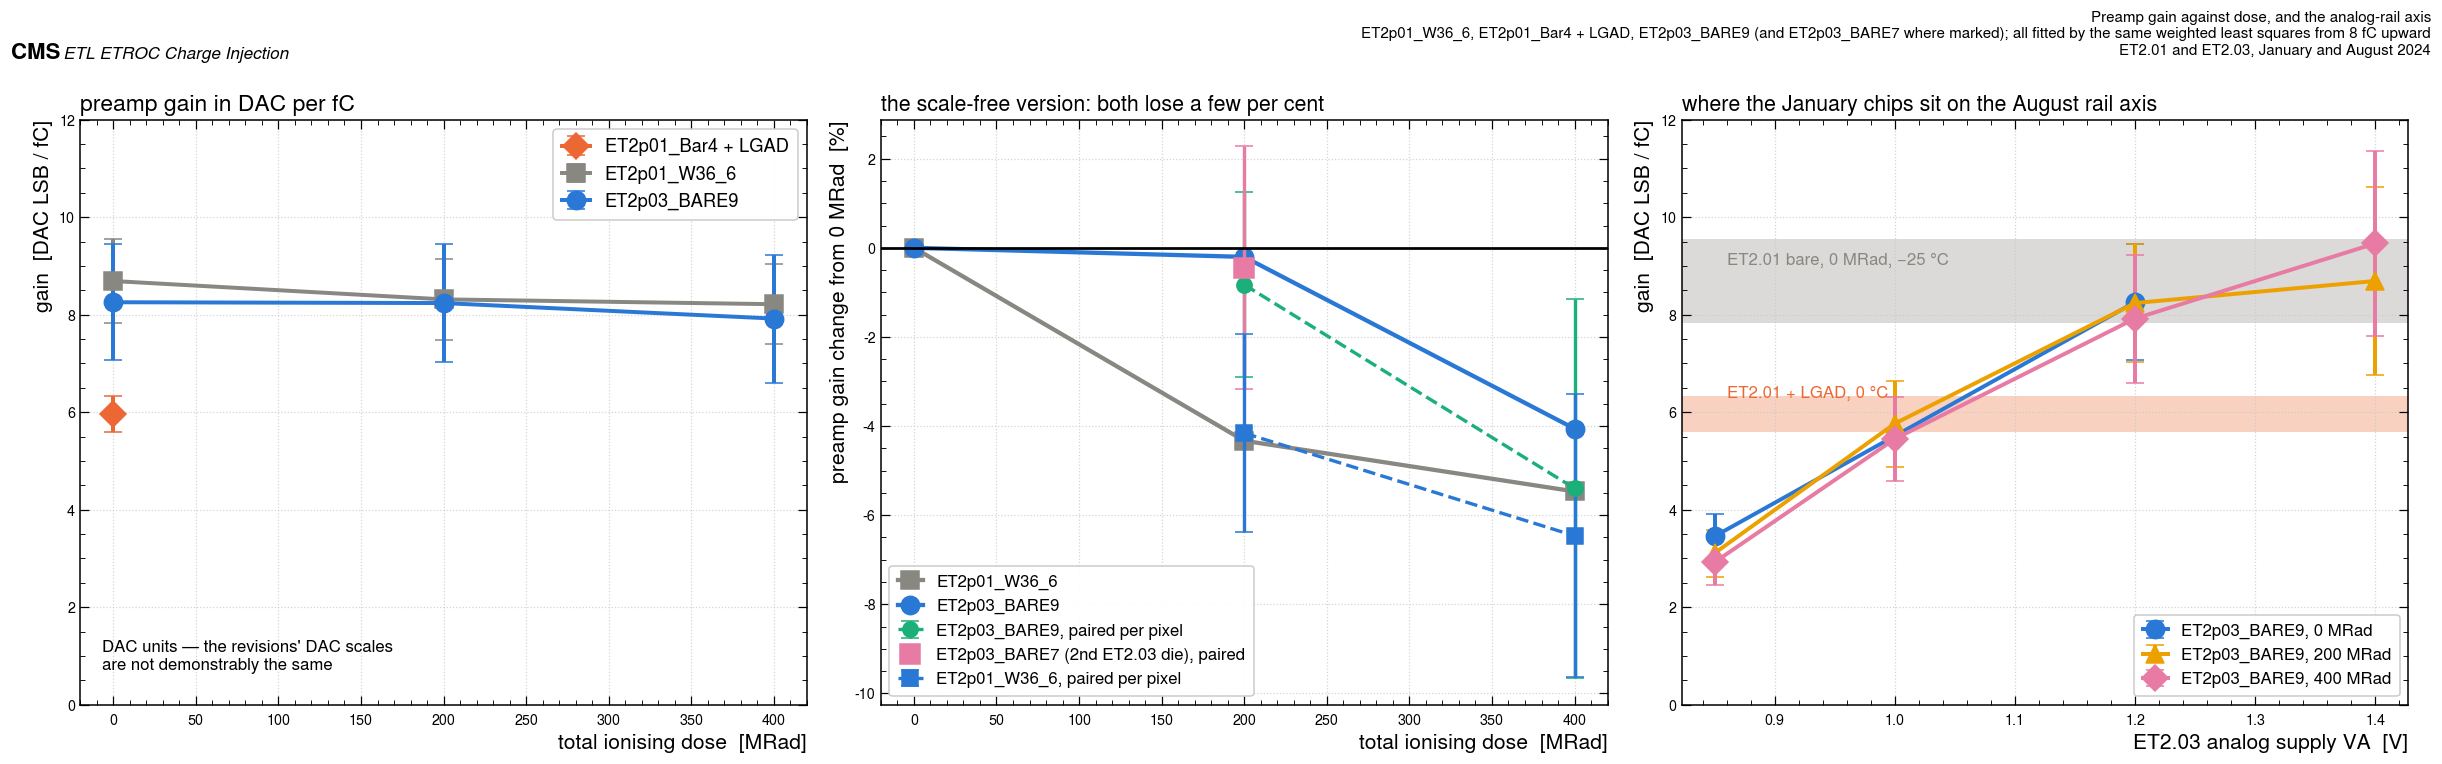

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
ax = axs[0]
for ds, sub in GCMP.groupby("data_set"):
    sub = sub.sort_values("dose")
    ax.errorbar(sub.dose, sub.gain_dac_per_fc, yerr=sub.gain_sem, fmt="-", marker=SMK[ds], ms=12,
                lw=2.6, color=SCOL[ds], capsize=6, label=DIE[ds])
ax.set_xlabel("total ionising dose  [MRad]")
ax.set_ylabel("gain  [DAC LSB / fC]")
ax.set_ylim(0, 12)
ax.legend(fontsize=12)
ax.text(0.03, 0.06, "DAC units — the revisions' DAC scales\nare not demonstrably the same",
        transform=ax.transAxes, fontsize=11)
ax.set_title("preamp gain in DAC per fC", loc="left", fontsize=15)

ax = axs[1]
for ds, sub in GCMP.dropna(subset=["rel_to_0MRad"]).groupby("data_set"):
    sub = sub.sort_values("dose")
    ax.plot(sub.dose, 100 * (sub.rel_to_0MRad - 1), "-", marker=SMK[ds], ms=12, lw=2.8,
            color=SCOL[ds], label=DIE[ds])
pp = P03[(P03.va == 1.20) & (P03.dose_from == 0)].sort_values("dose_to")
ax.errorbar(pp.dose_to, pp.gain_change_pct, yerr=100 * pp.gain_ratio_sem, fmt="o--", ms=10,
            lw=2.2, color=Q.C_AQUA, capsize=6, label=f"{DIE[K03]}, paired per pixel")
pp7 = P03_B7[(P03_B7.va == 1.20) & (P03_B7.dose_from == 0)].sort_values("dose_to")
if len(pp7):
    ax.errorbar(pp7.dose_to, pp7.gain_change_pct, yerr=100 * pp7.gain_ratio_sem, fmt="s", ms=13,
                lw=2.2, color=Q.C_MAG, capsize=6, label=f"{DIE7} (2nd ET2.03 die), paired")
pp1 = P01[P01.dose_from == 0].sort_values("dose_to")
ax.errorbar(pp1.dose_to, pp1.gain_change_pct, yerr=100 * pp1.gain_ratio_sem, fmt="s--", ms=10,
            lw=2.2, color=Q.C_BLUE, capsize=6, label=f"{DIE[K01]}, paired per pixel")
ax.axhline(0, color="black", lw=1.8)
ax.set_xlabel("total ionising dose  [MRad]")
ax.set_ylabel("preamp gain change from 0 MRad  [%]")
ax.legend(fontsize=11)
ax.set_title("the scale-free version: both lose a few per cent", loc="left", fontsize=14)

ax = axs[2]
for dose, cc, mk in [(0.0, Q.C_BLUE, "o"), (200.0, Q.C_YELLOW, "^"), (400.0, Q.C_MAG, "D")]:
    s = g03[g03.dose == dose].sort_values("va")
    if not len(s):
        continue
    ax.errorbar(s.va, s.gain_dac_per_fc, yerr=s.gain_sem, fmt="-", marker=mk, ms=12, lw=2.6,
                color=cc, capsize=6, label=f"{DIE[K03]}, {int(dose)} MRad")
ax.axhspan(g01.loc[(0, -25), "gain_dac_per_fc"] - g01.loc[(0, -25), "gain_sem"],
           g01.loc[(0, -25), "gain_dac_per_fc"] + g01.loc[(0, -25), "gain_sem"],
           color=SCOL[K01], alpha=0.30, lw=0)
ax.text(0.86, g01.loc[(0, -25), "gain_dac_per_fc"] + 0.35, "ET2.01 bare, 0 MRad, −25 °C",
        fontsize=11, color=SCOL[K01])
ax.axhspan(gh.loc[HYB_PRIMARY, "gain_dac_per_fc"] - gh.loc[HYB_PRIMARY, "gain_sem"],
           gh.loc[HYB_PRIMARY, "gain_dac_per_fc"] + gh.loc[HYB_PRIMARY, "gain_sem"],
           color=SCOL[K02], alpha=0.30, lw=0)
ax.text(0.86, gh.loc[HYB_PRIMARY, "gain_dac_per_fc"] + 0.35, "ET2.01 + LGAD, 0 °C",
        fontsize=11, color=SCOL[K02])
ax.set_xlabel("ET2.03 analog supply VA  [V]")
ax.set_ylabel("gain  [DAC LSB / fC]")
ax.set_ylim(0, 12)
ax.legend(fontsize=11, loc="lower right")
ax.set_title("where the January chips sit on the August rail axis", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "Preamp gain against dose, and the analog-rail axis",
             tag="ET2p01_W36_6, ET2p01_Bar4 + LGAD, ET2p03_BARE9 (and ET2p03_BARE7 where marked); "
                 "all fitted by the same weighted least squares from 8 fC upward",
             scale=0.62, campaign=Q.XCAMP_CAMPAIGN)
Q.save_fig(fig, "xcamp_fig2_gain")
plt.show()

The right-hand panel is the one to be careful with. It looks as though the ET2.01 chips "are" at
some particular VA on the ET2.03 curve, and that is **not** what it shows: the January chips'
rails were not recorded, their DAC scale is set by a different reference, and their pixel sets
and temperatures differ. What it does show is that **the entire spread between the three data
sets in DAC per fC — a factor of about 1.7 — is smaller than the range one chip covers when its
own analog supply is moved from 0.85 to 1.40 V.** Any comparison of absolute gain between
campaigns that do not record their rails is therefore weakly constrained at best.

## 4. Turn-off referred to baseline, against charge

This is the comparison that is closest to scale-free: each curve is `turn-off − BL` for the
condition it was measured in, so a common offset in the DAC scale cancels. A *multiplicative*
scale difference does not cancel, which is why the ET2.03 rail dependence is drawn alongside.

In [8]:
o01 = O01[(O01.dose == 0) & (O01.temp == 12)].groupby("charge").trig_turnoff_offset.agg(["mean", "std"])
o01m = O01[(O01.dose == 400) & (O01.temp == -25)].groupby("charge").trig_turnoff_offset.agg(["mean", "std"])
oh = OH[OH.config == HYB_PRIMARY].groupby("charge_fC").trig_turnoff_offset.agg(["mean", "std"])
o03 = O03[O03.config == CFG03].groupby("charge_fC").turnoff_offset.agg(["mean", "std"])
o03m = O03[O03.config == G03[(G03.chip == "ET2p03_BARE9") & (G03.dose == 400) & (G03.va == 1.20)].config.iloc[0]]
o03m = o03m.groupby("charge_fC").turnoff_offset.agg(["mean", "std"])
TOFF = pd.concat([o01.assign(data_set=K01, condition="0 MRad, +12 °C"),
                  o01m.assign(data_set=K01, condition="400 MRad, −25 °C"),
                  oh.assign(data_set=K02, condition="0 MRad, 0 °C, HV 210 V"),
                  o03.assign(data_set=K03, condition="0 MRad, VA 1.20 V"),
                  o03m.assign(data_set=K03, condition="400 MRad, VA 1.20 V")])
TOFF.index.name = "charge_fC"
TOFF = TOFF.reset_index().rename(columns={"mean": "turnoff_offset_mean", "std": "pixel_rms"})
TOFF.to_csv(Q.OUTDIR / "xcamp_turnoff_vs_charge.csv", index=False)
print(TOFF.round(2).to_string(index=False))
common = sorted(set(o01.index) & set(oh.index) & set(o03.index))
print("\ncharges measured by all three: %s fC" % common)
print("turn-off above baseline there [DAC]:")
for c in common:
    print("  %2d fC:  ET2.01 bare %6.1f   ET2.01+LGAD %6.1f   ET2.03 bare %6.1f   "
          "(hybrid/bare %.2f, ET2.03/ET2.01 %.2f)"
          % (c, o01.loc[c, "mean"], oh.loc[c, "mean"], o03.loc[c, "mean"],
             oh.loc[c, "mean"] / o01.loc[c, "mean"], o03.loc[c, "mean"] / o01.loc[c, "mean"]))

 charge_fC  turnoff_offset_mean  pixel_rms      data_set              condition
       5.0                45.94       6.24   ET2.01 bare         0 MRad, +12 °C
       6.0                47.34       7.41   ET2.01 bare         0 MRad, +12 °C
       8.0                55.21      14.98   ET2.01 bare         0 MRad, +12 °C
      15.0               116.03      37.23   ET2.01 bare         0 MRad, +12 °C
      22.0               187.77      58.03   ET2.01 bare         0 MRad, +12 °C
      27.0               232.09      71.31   ET2.01 bare         0 MRad, +12 °C
       5.0                49.77       7.31   ET2.01 bare       400 MRad, −25 °C
       6.0                52.17       9.60   ET2.01 bare       400 MRad, −25 °C
       8.0                60.12      19.94   ET2.01 bare       400 MRad, −25 °C
      15.0               117.39      43.85   ET2.01 bare       400 MRad, −25 °C
      22.0               177.44      60.68   ET2.01 bare       400 MRad, −25 °C
      27.0               215.11      72.

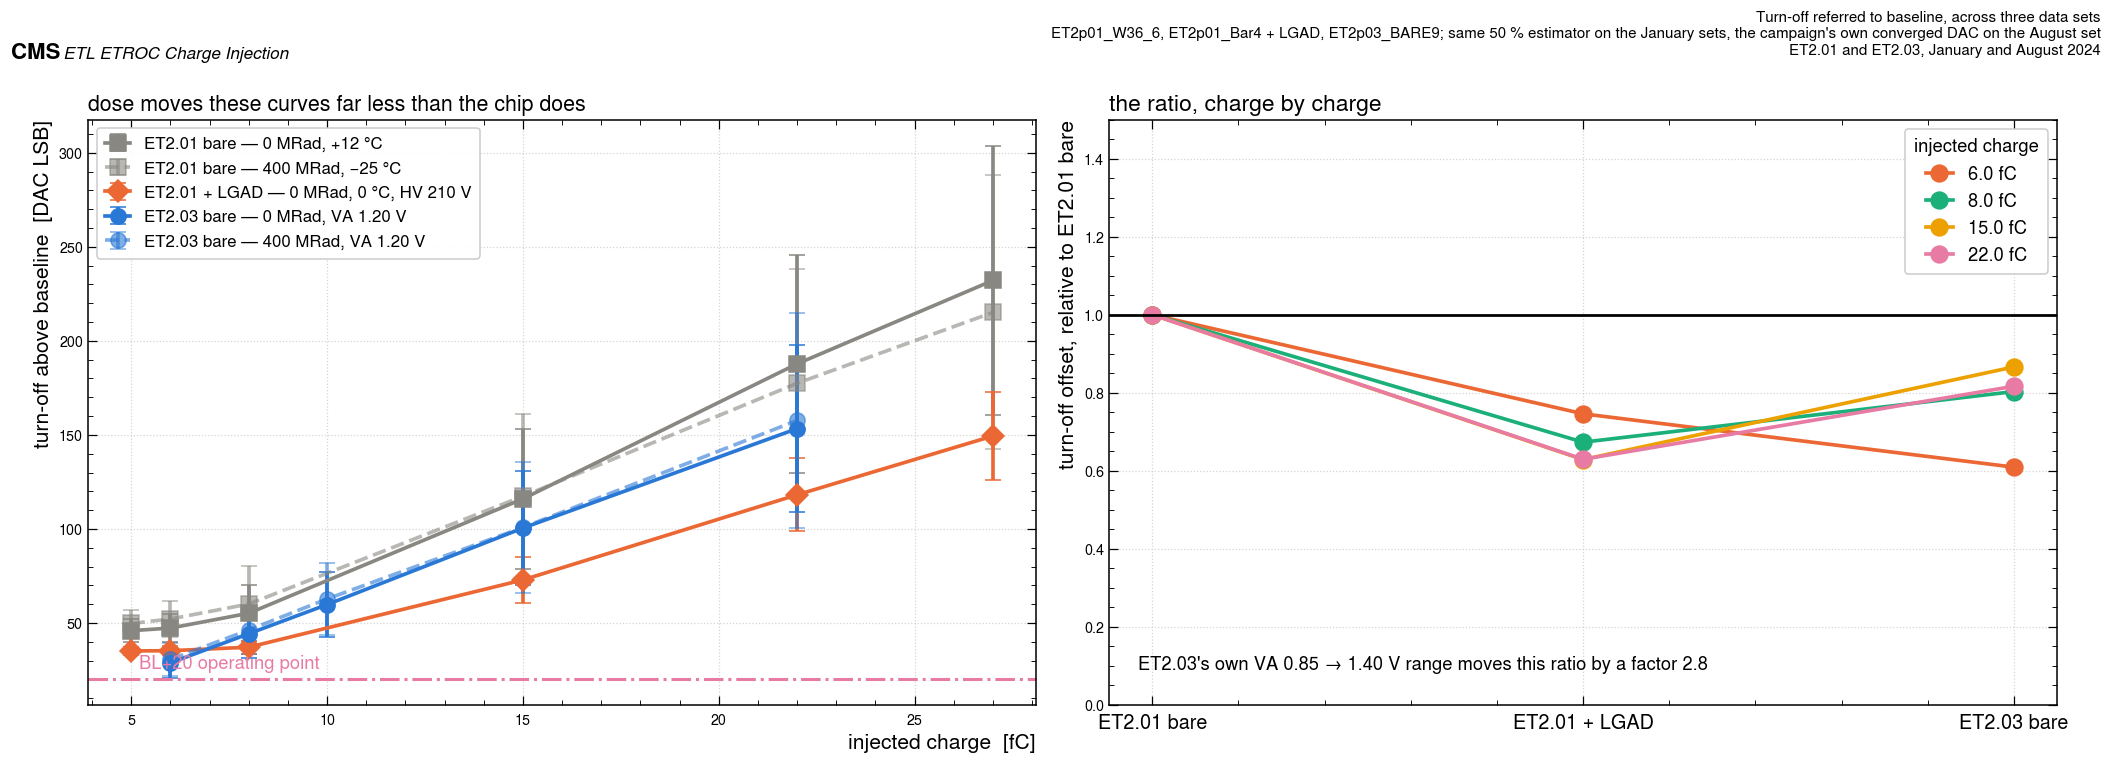

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(19, 6.4))
ax = axs[0]
for tab, ds, cond, ls in [(o01, K01, "0 MRad, +12 °C", "-"), (o01m, K01, "400 MRad, −25 °C", "--"),
                          (oh, K02, "0 MRad, 0 °C, HV 210 V", "-"),
                          (o03, K03, "0 MRad, VA 1.20 V", "-"), (o03m, K03, "400 MRad, VA 1.20 V", "--")]:
    ax.errorbar(tab.index, tab["mean"], yerr=tab["std"], fmt=ls, marker=SMK[ds], ms=10, lw=2.4,
                color=SCOL[ds], capsize=5, alpha=1.0 if ls == "-" else 0.6,
                label=f"{ds} — {cond}")
ax.axhline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2)
ax.text(5.2, Q.OP_OFFSET + 6, "BL+20 operating point", color=Q.C_MAG, fontsize=12)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("turn-off above baseline  [DAC LSB]")
ax.legend(fontsize=11, loc="upper left")
ax.set_title("dose moves these curves far less than the chip does", loc="left", fontsize=14)

ax = axs[1]
for c, cc in zip(common, [Q.CCOL[x] for x in common]):
    vals = [o01.loc[c, "mean"], oh.loc[c, "mean"], o03.loc[c, "mean"]]
    ax.plot([0, 1, 2], [v / vals[0] for v in vals], "-o", ms=11, lw=2.4, color=cc, label=f"{c} fC")
ax.axhline(1.0, color="black", lw=1.8)
g03_va = G03[(G03.chip == "ET2p03_BARE9") & (G03.dose == 200)].sort_values("va")
ax.set_xticks([0, 1, 2])
ax.set_xticklabels([K01, K02, K03], fontsize=13)
ax.set_ylabel("turn-off offset, relative to ET2.01 bare")
ax.legend(fontsize=12, title="injected charge", title_fontsize=12)
ax.set_ylim(0, 1.5)
ax.text(0.03, 0.06, "ET2.03's own VA 0.85 → 1.40 V range moves this ratio by a factor %.1f"
        % (g03_va.gain_dac_per_fc.iloc[-1] / g03_va.gain_dac_per_fc.iloc[0]),
        transform=ax.transAxes, fontsize=12)
ax.set_title("the ratio, charge by charge", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "Turn-off referred to baseline, across three data sets",
             tag="ET2p01_W36_6, ET2p01_Bar4 + LGAD, ET2p03_BARE9; same 50 % estimator on the "
                 "January sets, the campaign's own converged DAC on the August set",
             scale=0.62, campaign=Q.XCAMP_CAMPAIGN)
Q.save_fig(fig, "xcamp_fig3_turnoff")
plt.show()

## 5. TOT against charge at the operating point

TOT is the charge proxy the offline time-walk correction consumes, so its response to a known
charge is the most directly transferable measurement in this folder — and it is the one that
transfers worst.

**RFSel is not recorded on any of the three data sets.** It sets the preamplifier feedback
resistance and therefore fixes TOT directly. Every difference in this section is therefore an
upper bound on a real difference, and none of it can be attributed to the sensor, the revision
or the dose without knowing RFSel.

In [10]:
t01 = T01[T01.offset == 20].set_index("charge_fC")
th = TH[TH.offset == 20].set_index("charge_fC")
t03 = T03[(T03.config == CFG03) & (T03.offset == 20)].set_index("charge_fC")
TOTC = pd.concat([
    t01[["tot_code_mean", "tot_code_pixel_rms", "tot_ns_mean", "n_pixels"]].assign(data_set=K01),
    th[["tot_code_mean", "tot_code_pixel_rms", "tot_ns_mean", "n_pixels"]].assign(data_set=K02),
    t03[["tot_code_mean", "tot_code_pixel_rms", "tot_ns_mean", "n_pixels"]].assign(data_set=K03)])
TOTC.to_csv(Q.OUTDIR / "xcamp_tot_at_bl20.csv")
print(TOTC.round(3).to_string())
print("\nat the charges all three measured:")
for c in common:
    print("  %2d fC:  ET2.01 bare %5.1f code (%.2f ns)   ET2.01+LGAD %5.1f (%.2f ns)   "
          "ET2.03 bare %5.1f (%.2f ns)"
          % (c, t01.loc[c, "tot_code_mean"], t01.loc[c, "tot_ns_mean"],
             th.loc[c, "tot_code_mean"], th.loc[c, "tot_ns_mean"],
             t03.loc[c, "tot_code_mean"], t03.loc[c, "tot_ns_mean"]))
print("\nIn nanoseconds the two bare dies agree to within about %.0f %% at 15 fC, while the hybrid"
      % abs(100 * (t03.loc[15, "tot_ns_mean"] / t01.loc[15, "tot_ns_mean"] - 1)))
print("sits %.1f times higher. TOT in *codes* is not comparable across data sets at all, because"
      % (th.loc[15, "tot_code_mean"] / t01.loc[15, "tot_code_mean"]))
print("one code is 3.125 ns / CAL and CAL differs: %.0f, %.0f and %.0f on the three."
      % (B01["cal_median"], CAL_HYB, B03["cal_median"]))

           tot_code_mean  tot_code_pixel_rms  tot_ns_mean  n_pixels       data_set
charge_fC                                                                         
5.0               26.851              10.817        0.988         9    ET2.01 bare
6.0               32.017               9.297        1.173        12    ET2.01 bare
8.0               41.826               4.725        1.532        12    ET2.01 bare
15.0              49.873               2.191        1.830        12    ET2.01 bare
22.0              52.288               2.080        1.920        12    ET2.01 bare
27.0              53.399               2.274        1.961        12    ET2.01 bare
5.0               24.136               4.522        0.868         5  ET2.01 + LGAD
6.0               40.931              12.611        1.462         8  ET2.01 + LGAD
8.0               60.028              11.053        2.147         9  ET2.01 + LGAD
15.0              84.939               6.374        3.041         9  ET2.01 + LGAD
22.0

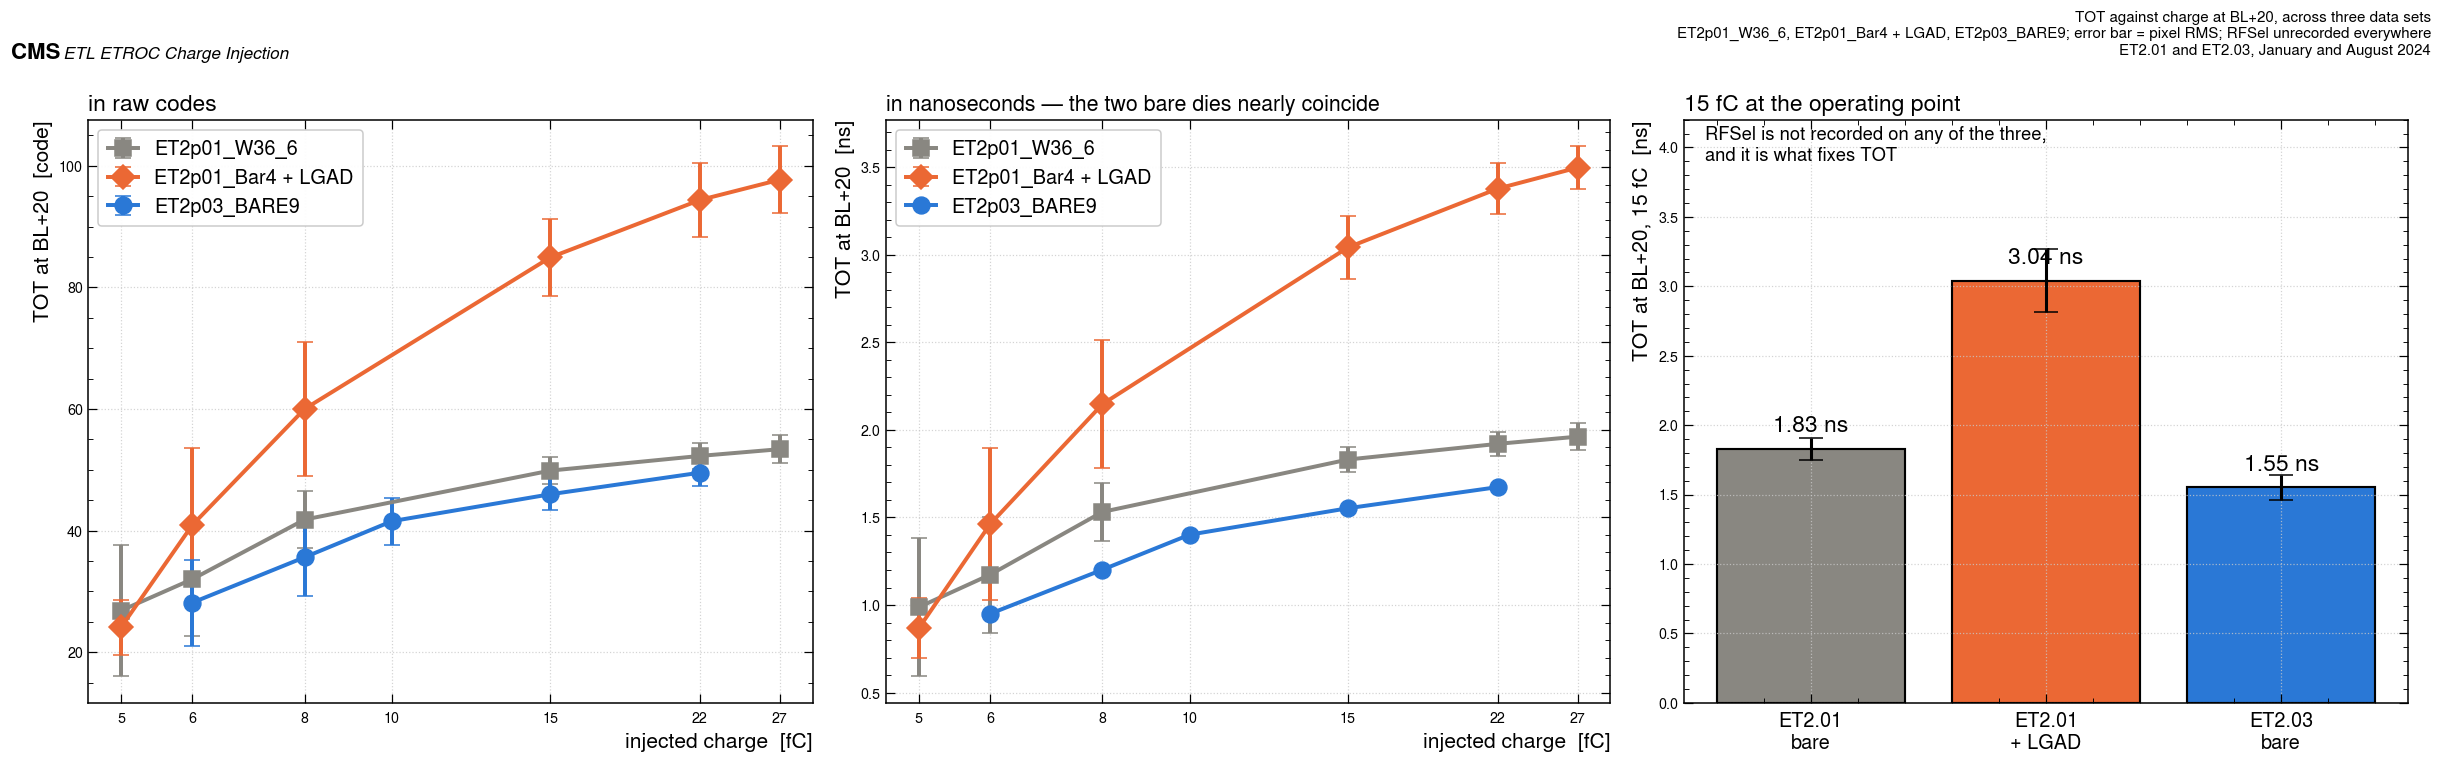

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
ax = axs[0]
for tab, ds in [(t01, K01), (th, K02), (t03, K03)]:
    ax.errorbar(tab.index, tab.tot_code_mean, yerr=tab.tot_code_pixel_rms, fmt="-", marker=SMK[ds],
                ms=11, lw=2.6, color=SCOL[ds], capsize=5, label=DIE[ds])
Q.charge_axis(ax, charges=sorted(int(c) for c in set(list(t01.index) + list(t03.index))))
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOT at BL+20  [code]")
ax.legend(fontsize=13)
ax.set_title("in raw codes", loc="left", fontsize=15)

ax = axs[1]
for tab, ds in [(t01, K01), (th, K02), (t03, K03)]:
    ax.errorbar(tab.index, tab.tot_ns_mean, yerr=tab.tot_ns_pixel_rms if "tot_ns_pixel_rms" in tab else None,
                fmt="-", marker=SMK[ds], ms=11, lw=2.6, color=SCOL[ds], capsize=5, label=DIE[ds])
Q.charge_axis(ax, charges=sorted(int(c) for c in set(list(t01.index) + list(t03.index))))
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOT at BL+20  [ns]")
ax.legend(fontsize=13)
ax.set_title("in nanoseconds — the two bare dies nearly coincide", loc="left", fontsize=14)

ax = axs[2]
labels = ["ET2.01\nbare", "ET2.01\n+ LGAD", "ET2.03\nbare"]
vals = [t01.loc[15, "tot_ns_mean"], th.loc[15, "tot_ns_mean"], t03.loc[15, "tot_ns_mean"]]
errs = [t01.loc[15, "tot_code_pixel_rms"] * t01.loc[15, "tot_ns_mean"] / t01.loc[15, "tot_code_mean"],
        th.loc[15, "tot_code_pixel_rms"] * th.loc[15, "tot_ns_mean"] / th.loc[15, "tot_code_mean"],
        t03.loc[15, "tot_code_pixel_rms"] * t03.loc[15, "tot_ns_mean"] / t03.loc[15, "tot_code_mean"]]
ax.bar(range(3), vals, yerr=errs, capsize=8, color=[SCOL[K01], SCOL[K02], SCOL[K03]],
       edgecolor="black", lw=1.4)
for i, v in enumerate(vals):
    ax.text(i, v + 0.12, f"{v:.2f} ns", ha="center", fontsize=15)
ax.set_xticks(range(3))
ax.set_xticklabels(labels, fontsize=13)
ax.set_ylabel("TOT at BL+20, 15 fC  [ns]")
ax.set_ylim(0, 4.2)
ax.text(0.03, 0.93, "RFSel is not recorded on any of the three,\nand it is what fixes TOT",
        transform=ax.transAxes, fontsize=12)
ax.set_title("15 fC at the operating point", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "TOT against charge at BL+20, across three data sets",
             tag="ET2p01_W36_6, ET2p01_Bar4 + LGAD, ET2p03_BARE9; error bar = pixel RMS; "
                 "RFSel unrecorded everywhere", scale=0.62,
             campaign=Q.XCAMP_CAMPAIGN)
Q.save_fig(fig, "xcamp_fig4_tot")
plt.show()

## 6. TOA jitter at the operating point

The same warning as in every notebook of this folder, and it applies to all three data sets at
once: **the injection is synchronous with the clock and no sensor is generating the signal**, so
above about 8 fC the measured jitter closes on the TDC quantisation floor `LSB/√12` and is a
limit rather than a resolution. "Closes on" rather than "sits at": the `over_floor` column below
gives the ratio point by point, and at 15 fC it is 1.18, 2.02 and 1.69 on the three data sets —
only the bare ET2.01 is really at its floor. None of these numbers may be compared with a beam per-board time
resolution. The physics is in the low-charge rise.

The floors themselves differ, because one TOA code is `3.125 ns / CAL` and CAL differs between
the data sets, so each is drawn with its own.

In [12]:
j01 = J01.set_index("charge")
j03 = J03[(J03.config == CFG03) & (J03.offset == 20)].set_index("charge_fC")
jh = BVH[BVH.quantity.str.startswith("TOA jitter at BL+20")].copy()
jh["charge"] = [int(q.split(",")[-1].replace("fC", "").strip()) for q in jh.quantity]
jh = jh.set_index("charge")
fl01, fl03 = B01["quantisation_floor_ps"], B03["quantisation_floor_ps"]
flh = float(BVH[BVH.quantity == "TDC quantisation floor"].hybrid.iloc[0])
print("TDC quantisation floor:  ET2.01 bare %.2f ps   ET2.01+LGAD %.2f ps   ET2.03 bare %.2f ps"
      % (fl01, flh, fl03))
print("(one TOA code: %.1f, %.1f and %.1f ps, i.e. CAL %.0f, %.0f and %.0f)"
      % (B01["toa_lsb_ps"], flh * np.sqrt(12), B03["toa_lsb_ps"],
         B01["cal_median"], CAL_HYB, B03["cal_median"]))
JCMP = pd.DataFrame([
    dict(charge_fC=c, data_set=K01, jitter_ps=j01.loc[c, "mean"], pixel_rms=j01.loc[c, "std"],
         n_pixels=int(j01.loc[c, "size"]), floor_ps=fl01, over_floor=j01.loc[c, "mean"] / fl01)
    for c in j01.index] + [
    dict(charge_fC=c, data_set=K02, jitter_ps=float(jh.loc[c, "hybrid"]), pixel_rms=np.nan,
         n_pixels=9, floor_ps=flh, over_floor=float(jh.loc[c, "hybrid"]) / flh)
    for c in jh.index] + [
    dict(charge_fC=c, data_set=K03, jitter_ps=j03.loc[c, "jitter_mean"],
         pixel_rms=j03.loc[c, "jitter_pixel_rms"], n_pixels=int(j03.loc[c, "n_pixels"]),
         floor_ps=fl03, over_floor=j03.loc[c, "jitter_mean"] / fl03)
    for c in j03.index])
JCMP.to_csv(Q.OUTDIR / "xcamp_jitter_at_bl20.csv", index=False)
print()
print(JCMP.round(2).to_string(index=False))
print("\nNotebook 02 exports the hybrid's jitter at 8 and 15 fC only (through bare_vs_hybrid.csv),")
print("so the hybrid contributes two points here rather than a curve. Notebook 03's six-pixel")
print("means are pulled around by single pixels at low charge; its medians are")
print("  %s ps" % {int(c): round(v, 1) for c, v in B03["jitter_off20_median_by_charge"].items()})
print("against the means")
print("  %s ps" % {int(c): round(v, 1) for c, v in B03["jitter_off20_by_charge"].items()})

TDC quantisation floor:  ET2.01 bare 5.37 ps   ET2.01+LGAD 5.24 ps   ET2.03 bare 4.88 ps
(one TOA code: 18.6, 18.1 and 16.9 ps, i.e. CAL 168, 172 and 185)

 charge_fC      data_set  jitter_ps  pixel_rms  n_pixels  floor_ps  over_floor
       5.0   ET2.01 bare      23.88      13.12         9      5.37        4.45
       6.0   ET2.01 bare      22.07      16.00        12      5.37        4.11
       8.0   ET2.01 bare      10.78       3.02        12      5.37        2.01
      15.0   ET2.01 bare       6.36       3.01        12      5.37        1.18
      22.0   ET2.01 bare       7.42       2.72        12      5.37        1.38
      27.0   ET2.01 bare       6.61       3.23        12      5.37        1.23
       8.0 ET2.01 + LGAD      27.66        NaN         9      5.24        5.28
      15.0 ET2.01 + LGAD      10.58        NaN         9      5.24        2.02
       6.0   ET2.03 bare      22.69      12.42         5      4.88        4.65
       8.0   ET2.03 bare      13.09       5.34        

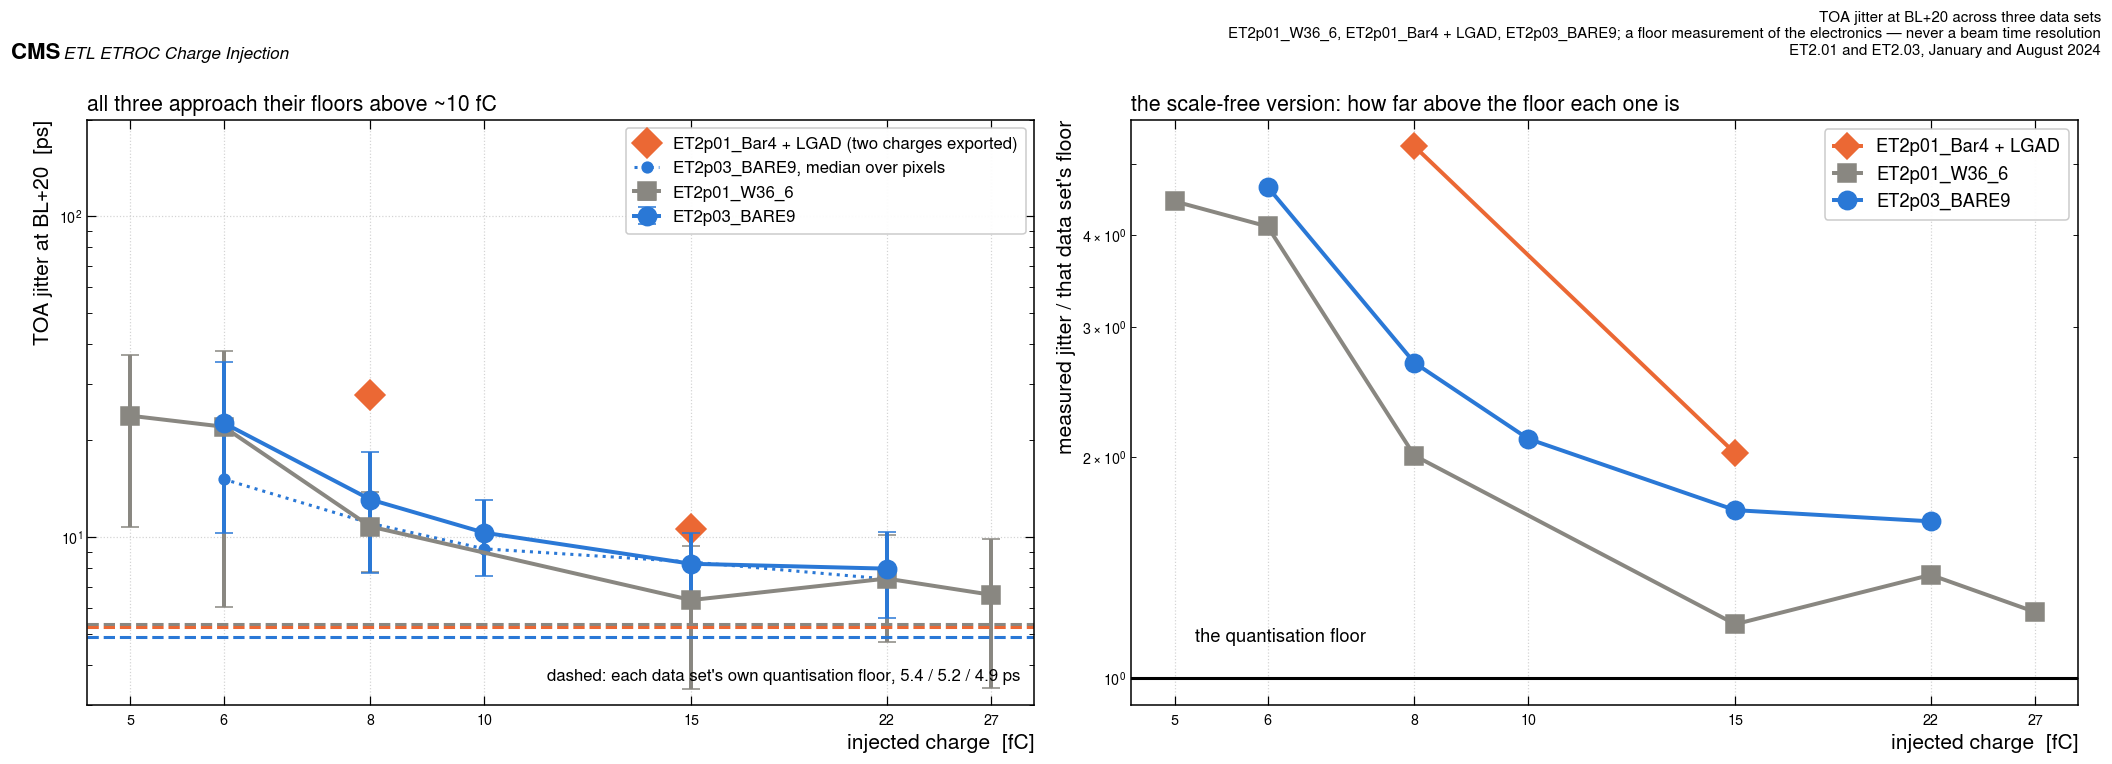

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(19, 6.4))
ax = axs[0]
ax.errorbar(j01.index, j01["mean"], yerr=j01["std"], fmt="-", marker=SMK[K01], ms=12, lw=2.6,
            color=SCOL[K01], capsize=6, label=DIE[K01])
ax.plot(jh.index, jh.hybrid, "D", ms=14, color=SCOL[K02], label=DIE[K02] + " (two charges exported)")
ax.errorbar(j03.index, j03.jitter_mean, yerr=j03.jitter_pixel_rms, fmt="-", marker=SMK[K03],
            ms=12, lw=2.6, color=SCOL[K03], capsize=6, label=DIE[K03])
ax.plot(j03.index, j03.jitter_median, ":", marker="o", ms=7, lw=2.0, color=SCOL[K03],
        label=DIE[K03] + ", median over pixels")
for fl, ds in [(fl01, K01), (flh, K02), (fl03, K03)]:
    ax.axhline(fl, color=SCOL[ds], ls="--", lw=2.0)
ax.text(0.985, 0.035, "dashed: each data set's own quantisation floor, %.1f / %.1f / %.1f ps"
        % (fl01, flh, fl03), transform=ax.transAxes, fontsize=11, ha="right", va="bottom")
Q.charge_axis(ax, charges=sorted(int(c) for c in set(list(j01.index) + list(j03.index))))
ax.set_yscale("log")
ax.set_ylim(3, 200)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOA jitter at BL+20  [ps]")
ax.legend(fontsize=11)
ax.set_title("all three approach their floors above ~10 fC", loc="left", fontsize=14)

ax = axs[1]
for ds, sub in JCMP.groupby("data_set"):
    sub = sub.sort_values("charge_fC")
    ax.plot(sub.charge_fC, sub.over_floor, "-", marker=SMK[ds], ms=12, lw=2.6, color=SCOL[ds],
            label=DIE[ds])
ax.axhline(1.0, color="black", lw=2)
ax.text(5.2, 1.12, "the quantisation floor", fontsize=12)
Q.charge_axis(ax, charges=sorted(int(c) for c in set(list(j01.index) + list(j03.index))))
ax.set_yscale("log")
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("measured jitter / that data set's floor")
ax.legend(fontsize=12)
ax.set_title("the scale-free version: how far above the floor each one is", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "TOA jitter at BL+20 across three data sets",
             tag="ET2p01_W36_6, ET2p01_Bar4 + LGAD, ET2p03_BARE9; a floor measurement of the "
                 "electronics — never a beam time resolution",
             scale=0.62, campaign=Q.XCAMP_CAMPAIGN)
Q.save_fig(fig, "xcamp_fig5_jitter")
plt.show()

## 7. The threshold edge, the noise width and ENC

Three related quantities, and it matters which is which.

* **σ**, the shared-σ S-curve width, is a *charge-injection* measurement of the discriminator
  edge, in DAC.
* **NW**, the autocalibration noise width, is an *accumulator* measurement made by the chip
  itself, also in DAC. It is not the same definition as σ and the ratio between them is a data
  point, not a conversion.
* **ENC = σ / gain**, in electrons, is the only one of the three that is **free of the DAC
  scale**, because the scale appears in both numerator and denominator. It is therefore the
  right quantity to compare across chip revisions, and it is what this section leads with.

Notebook 03 measures NW two ways — the full width at half maximum of its in-configuration noise
scan, available at every condition, and the one autocalibration map the August campaign left
behind. Only the second is the same definition as the January campaigns', so it is the map value
that is compared here and the FWHM that is carried alongside.

In [14]:
s01 = S01[(S01.dose == 0) & (S01.temp == 12)].iloc[0]
sh = GH.set_index("config").loc[HYB_PRIMARY]
s03 = S03[S03.config == CFG03].iloc[0]
NOISE = pd.DataFrame([
    dict(quantity="S-curve width σ", unit="DAC", **{K01: B01["sigma_dac"], K02: sh.sigma_dac, K03: s03.sigma_dac},
         scale_free="no — DAC units"),
    dict(quantity="gain", unit="DAC/fC", **{K01: B01["gain_dac_per_fc"], K02: sh.gain_dac_per_fc,
                                            K03: s03.gain_dac_per_fc}, scale_free="no — DAC units"),
    dict(quantity="ENC = σ / gain", unit="electrons", **{K01: B01["enc_e"], K02: sh.ENC_e, K03: s03.ENC_e},
         scale_free="YES — the DAC scale cancels"),
    dict(quantity="autocalibration NW (map)", unit="DAC",
         **{K01: B01["nw_dac"], K02: sh.NW_map, K03: B03["nw_map_dac"]}, scale_free="no — DAC units"),
    dict(quantity="noise-peak FWHM", unit="DAC", **{K01: np.nan, K02: np.nan, K03: B03["nw_fwhm_dac"]},
         scale_free="no — and only ET2.03 measured it"),
    dict(quantity="NW(map) / σ", unit="—",
         **{K01: B01["nw_dac"] / B01["sigma_dac"], K02: sh.NW_map / sh.sigma_dac,
            K03: B03["nw_map_dac"] / s03.sigma_dac}, scale_free="YES — a ratio of two DAC quantities"),
])
NOISE.to_csv(Q.OUTDIR / "xcamp_noise_and_enc.csv", index=False)
print(NOISE.round(3).to_string(index=False))
print("\nENC ratios:  ET2.01+LGAD / ET2.01 bare  %.2f      ET2.03 bare / ET2.01 bare  %.2f"
      % (sh.ENC_e / B01["enc_e"], s03.ENC_e / B01["enc_e"]))
print("sigma ratios: ET2.01+LGAD / ET2.01 bare  %.2f      ET2.03 bare / ET2.01 bare  %.2f"
      % (sh.sigma_dac / B01["sigma_dac"], s03.sigma_dac / B01["sigma_dac"]))
print("gain ratios:  ET2.01+LGAD / ET2.01 bare  %.2f      ET2.03 bare / ET2.01 bare  %.2f"
      % (sh.gain_dac_per_fc / B01["gain_dac_per_fc"], s03.gain_dac_per_fc / B01["gain_dac_per_fc"]))
enc03 = {int(k): round(v) for k, v in B03["enc_by_dose_va120"].items()}
enc01 = dict(zip(S01[S01.temp == -25].dose.astype(int), S01[S01.temp == -25].enc.round(0)))
print("\nENC against dose:  ET2.01 bare at −25 °C %s e−" % enc01)
print("                   ET2.03 bare at VA 1.20 V %s e−" % enc03)
print("ET2.03 ENC against the analog rail at 200 MRad: %s e−"
      % {float(r.va): round(r.ENC_e) for _, r in S03[(S03.chip == "ET2p03_BARE9") & (S03.dose == 200)].sort_values("va").iterrows()})

                quantity      unit  ET2.01 bare  ET2.01 + LGAD  ET2.03 bare                          scale_free
         S-curve width σ       DAC        0.920          0.930        1.120                      no — DAC units
                    gain    DAC/fC        9.416          5.957        8.256                      no — DAC units
          ENC = σ / gain electrons      609.838        974.471      846.721         YES — the DAC scale cancels
autocalibration NW (map)       DAC        3.167          4.444        4.167                      no — DAC units
         noise-peak FWHM       DAC          NaN            NaN        2.989    no — and only ET2.03 measured it
             NW(map) / σ         —        3.442          4.779        3.720 YES — a ratio of two DAC quantities

ENC ratios:  ET2.01+LGAD / ET2.01 bare  1.60      ET2.03 bare / ET2.01 bare  1.39
sigma ratios: ET2.01+LGAD / ET2.01 bare  1.01      ET2.03 bare / ET2.01 bare  1.22
gain ratios:  ET2.01+LGAD / ET2.01 bare  0.63     

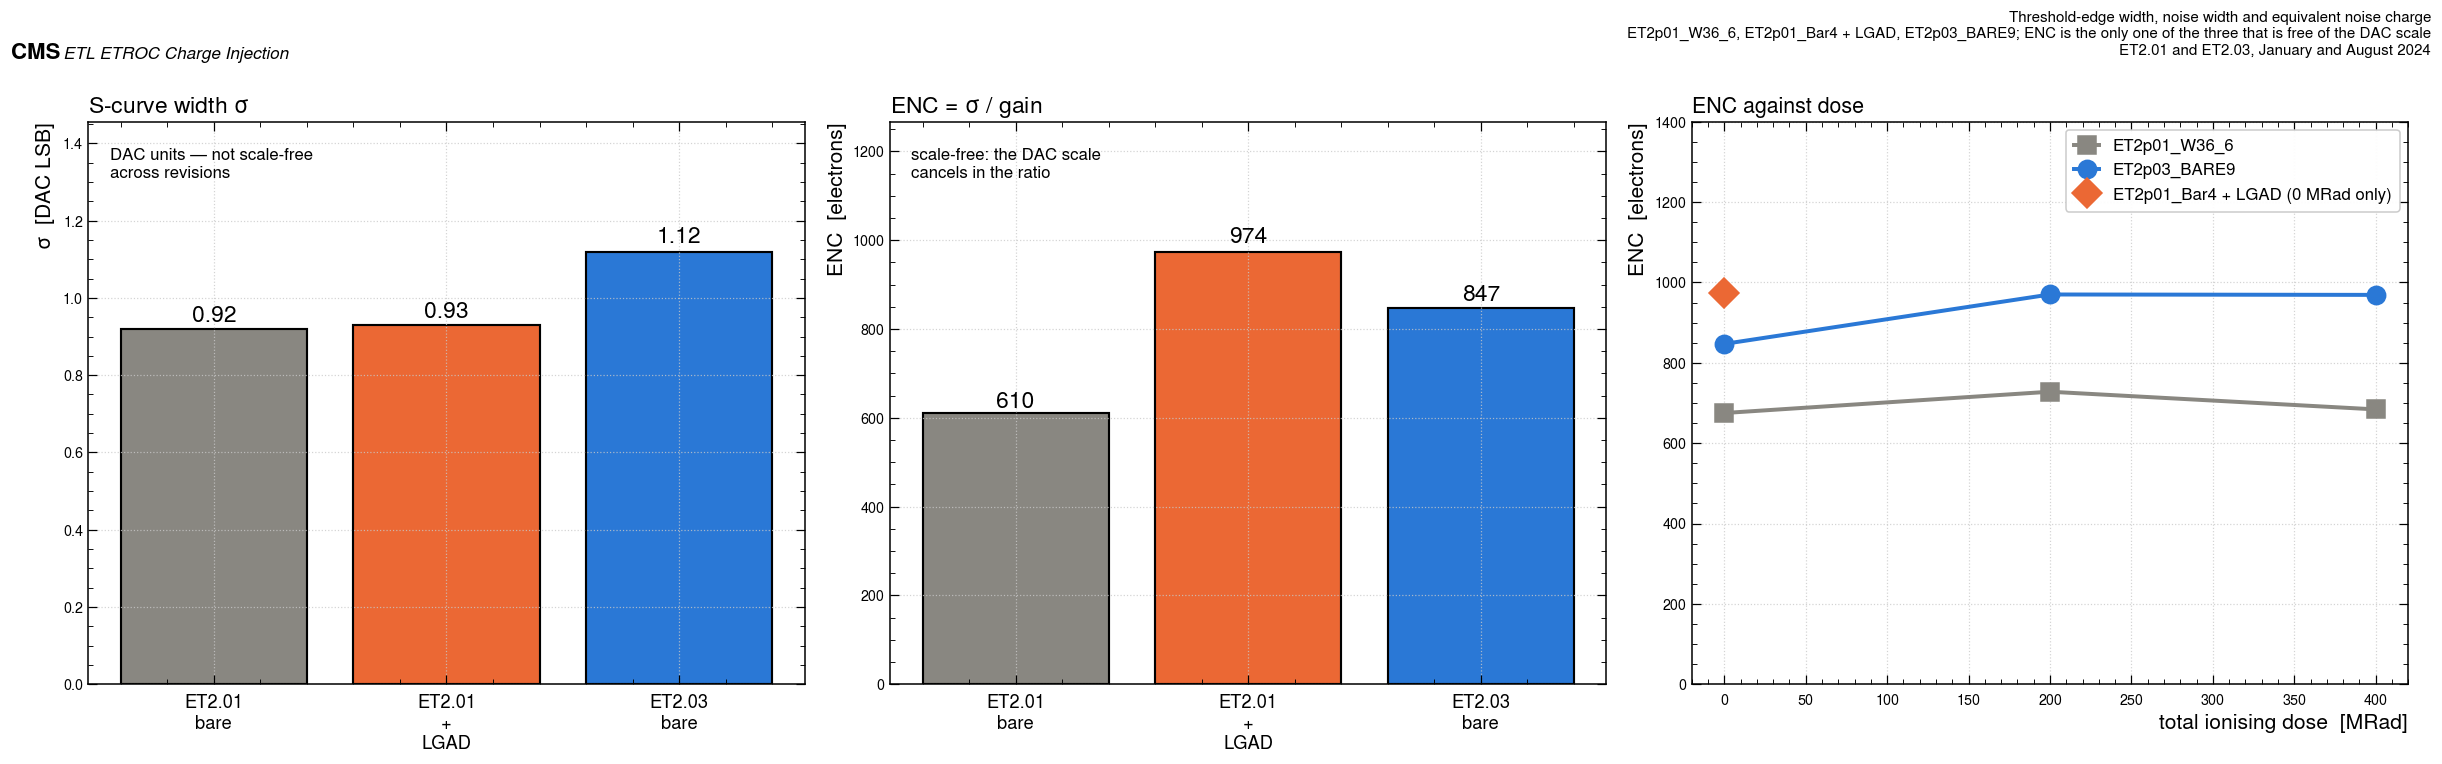

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6.4))
DS3 = [K01, K02, K03]


def three_bars(ax, vals, title, ylabel, fmt="%.2f", extra=None):
    ax.bar(range(3), vals, color=[SCOL[d] for d in DS3], edgecolor="black", lw=1.4)
    for i, v in enumerate(vals):
        ax.text(i, v * 1.02, fmt % v, ha="center", fontsize=15)
    ax.set_xticks(range(3))
    ax.set_xticklabels([d.replace(" ", "\n") for d in DS3], fontsize=12)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(vals) * 1.30)
    ax.set_title(title, loc="left", fontsize=15)
    if extra:
        ax.text(0.03, 0.90, extra, transform=ax.transAxes, fontsize=11)


three_bars(axs[0], [B01["sigma_dac"], sh.sigma_dac, s03.sigma_dac],
           "S-curve width $\\sigma$", "$\\sigma$  [DAC LSB]",
           extra="DAC units — not scale-free\nacross revisions")
three_bars(axs[1], [B01["enc_e"], sh.ENC_e, s03.ENC_e], "ENC = $\\sigma$ / gain",
           "ENC  [electrons]", fmt="%.0f", extra="scale-free: the DAC scale\ncancels in the ratio")
ax = axs[2]
for ds, dd, vv in [(K01, sorted(enc01), [enc01[d] for d in sorted(enc01)]),
                   (K03, sorted(enc03), [enc03[d] for d in sorted(enc03)])]:
    ax.plot(dd, vv, "-", marker=SMK[ds], ms=12, lw=2.6, color=SCOL[ds], label=DIE[ds])
ax.plot([0], [sh.ENC_e], SMK[K02], ms=14, color=SCOL[K02], label=DIE[K02] + " (0 MRad only)")
ax.set_xlabel("total ionising dose  [MRad]")
ax.set_ylabel("ENC  [electrons]")
ax.set_ylim(0, 1400)
ax.legend(fontsize=11)
ax.set_title("ENC against dose", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "Threshold-edge width, noise width and equivalent noise charge",
             tag="ET2p01_W36_6, ET2p01_Bar4 + LGAD, ET2p03_BARE9; ENC is the only one of the "
                 "three that is free of the DAC scale",
             scale=0.62, campaign=Q.XCAMP_CAMPAIGN)
Q.save_fig(fig, "xcamp_fig6_noise_enc")
plt.show()

## 8. Everything that differs between the three, in one table

Nothing below is a result. It is the list of reasons why every result above is weaker than it
looks, written out so that a reader can judge each comparison for themselves.

In [16]:
DIFFS = pd.DataFrame([
    dict(axis="chip revision", et2p01_bare="ET2.01", hybrid="ET2.01", et2p03_bare="ET2.03",
         why_it_matters="2.02 fixed the on-chip voltage reference (~167 mV low on 2.01); 2.03 added dummy bump pads. Source: ETROC2 Reference Manual rev 0.6, revision history"),
    dict(axis="voltage reference", et2p01_bare="external 1.0 V", hybrid="external 1.0 V",
         et2p03_bare="internal generator, powered from VA",
         why_it_matters="sets the DAC-to-mV scale; no read-back on any campaign, so no absolute DAC comparison is safe"),
    dict(axis="die", et2p01_bare="W36_6", hybrid="Bar4", et2p03_bare="BARE9 (0/200/400 MRad) and BARE7 (0/200 MRad)",
         why_it_matters="notebook 03 measures a large gain difference between two dies of the SAME revision; but BARE7 now has its own dose step, so the SIGN of the baseline shift is checked on a second die"),
    dict(axis="sensor", et2p01_bare="none", hybrid="LGAD, HV 210 V", et2p03_bare="none",
         why_it_matters="the hybrid's input capacitance is the point of notebook 02 and a confound everywhere else"),
    dict(axis="temperature", et2p01_bare="+12 °C (sweep), −25 °C (turn-off)", hybrid="0 °C",
         et2p03_bare="−23.6 °C, not scanned",
         why_it_matters="the two January sets disagree on the SIGN of the gain temperature coefficient; August cannot arbitrate"),
    dict(axis="analog rail VA", et2p01_bare="not recorded", hybrid="not recorded",
         et2p03_bare="0.85 / 1.00 / 1.20 / 1.40 V",
         why_it_matters="on ET2.03 the rail moves gain by ~2.8x — larger than every inter-campaign difference here"),
    dict(axis="digital rail VD", et2p01_bare="not recorded", hybrid="not recorded",
         et2p03_bare="1.20 V for every threshold scan; 0.90–1.45 V in the rail grid",
         why_it_matters="below 1.00 V the August chip produces no hits at all"),
    dict(axis="power mode", et2p01_bare="not recorded", hybrid="`highpower` (a directory tag)",
         et2p03_bare="not recorded",
         why_it_matters="notebook 02 shows the tag does not correspond to a repeatable supply current"),
    dict(axis="RFSel", et2p01_bare="not recorded", hybrid="not recorded", et2p03_bare="not recorded",
         why_it_matters="sets the feedback resistance and therefore gain AND TOT — the largest unquantified systematic in all three"),
    dict(axis="pixels", et2p01_bare="12: rows 0,1,3,12 × cols 2,8,14", hybrid="9: rows 2,8,14 × cols 2,8,14",
         et2p03_bare="6: rows 0,3,12 × cols 0,14",
         why_it_matters="no pixel is common to all three; every comparison is set-to-set, never pixel-to-pixel"),
    dict(axis="charges", et2p01_bare="5, 6, 8, 15, 22, 27 fC", hybrid="5, 6, 8, 15, 22, 27 fC",
         et2p03_bare="6, 8, 10, 15, 22 fC",
         why_it_matters="gain fits run 8–27 fC on the January sets and 8–22 fC on the August one"),
    dict(axis="dates", et2p01_bare="2024-01-11 to 01-19", hybrid="2024-01-11 to 01-19",
         et2p03_bare="2024-08-03 to 08-21",
         why_it_matters="seven months and a different facility; dose rate and annealing history are unrecorded on both"),
    dict(axis="turn-off estimator", et2p01_bare="interpolated 50 % of the trigger bit",
         hybrid="interpolated 50 % of the trigger bit",
         et2p03_bare="the search's own converged DAC — its binary search resolves a different feature",
         why_it_matters="notebook 03 measures the two definitions to agree to 0.0 ± 0.7 DAC wherever both are computable"),
    dict(axis="monitoring", et2p01_bare="LV supply log, 231 120 samples", hybrid="LV supply log + baseline history",
         et2p03_bare="none — one sentence of prose",
         why_it_matters="only the January sets can check whether the chip's operating point drifted during a scan"),
])
DIFFS.to_csv(Q.OUTDIR / "xcamp_conditions_differ.csv", index=False)
for _, r in DIFFS.iterrows():
    print("· %-20s  01: %-34s  02: %-34s  03: %s" % (r.axis, r.et2p01_bare, r.hybrid, r.et2p03_bare))
    print("  %s" % r.why_it_matters)

· chip revision         01: ET2.01                              02: ET2.01                              03: ET2.03
  2.02 fixed the on-chip voltage reference (~167 mV low on 2.01); 2.03 added dummy bump pads. Source: ETROC2 Reference Manual rev 0.6, revision history
· voltage reference     01: external 1.0 V                      02: external 1.0 V                      03: internal generator, powered from VA
  sets the DAC-to-mV scale; no read-back on any campaign, so no absolute DAC comparison is safe
· die                   01: W36_6                               02: Bar4                                03: BARE9 (0/200/400 MRad) and BARE7 (0/200 MRad)
  notebook 03 measures a large gain difference between two dies of the SAME revision; but BARE7 now has its own dose step, so the SIGN of the baseline shift is checked on a second die
· sensor                01: none                                02: LGAD, HV 210 V                      03: none
  the hybrid's input capacitance is the po

## 9. What a bench scan should settle, in order

Ranked by how much of the above each one would remove, not by how easy it is.

In [17]:
OPEN = pd.DataFrame([
    dict(rank=1, question="What is the threshold-DAC LSB, in millivolts, on each revision — and on ET2.03 how does it move with VA?",
         settled_by="A DAC transfer-function measurement: sweep the threshold DAC against an external voltmeter on one pixel, at VA 0.85/1.00/1.20/1.40 V, on an ET2.01 (or 2.02) board and an ET2.03 board.",
         what_it_removes="Everything in this notebook quoted in DAC becomes comparable across revisions: σ, NW, baseline shifts, gain in mV/fC. It is the single largest blocker."),
    dict(rank=2, question="What was RFSel on each of the three data sets, and how much does it move gain and TOT?",
         settled_by="Read RFSel back and scan it at fixed charge, recording TOT and turn-off at each setting.",
         what_it_removes="The TOT comparison of section 5 and the gain comparison of section 3, both of which are currently upper bounds on real differences."),
    dict(rank=3, question="Does the baseline-versus-dose sign flip follow the reference, the revision or the die?",
         settled_by="Two dies of the same revision through the same dose steps, with the reference switchable between internal and external on the same board.",
         what_it_removes="The four-way confound of section 2. This is the one measurement that would turn the folder's most striking observation into a result."),
    dict(rank=4, question="What is the temperature coefficient of gain, and what is its sign?",
         settled_by="One chip, one pixel set, a temperature scan from −25 to +25 °C at a fixed rail and a fixed bias, with the on-chip VTemp actually read out.",
         what_it_removes="The open disagreement between notebooks 01 and 02, which the August campaign cannot arbitrate because it did not scan temperature."),
    dict(rank=5, question="How much of the analog-rail dependence of gain is the front end and how much is the reference?",
         settled_by="The rail scan of notebook 03 repeated with an external reference, so that the DAC scale is fixed while VA moves.",
         what_it_removes="The ambiguity in section 13 of notebook 03, and with it the interpretation of the whole VA axis."),
    dict(rank=6, question="Is the chip-to-chip spread really ~20 % in gain, and how many dies does it take to know?",
         settled_by="The same six-pixel, five-charge scan on five or more dies of one revision at one condition.",
         what_it_removes="The die confound in every cross-campaign comparison here, currently bounded only by one BARE7-against-BARE9 pair."),
    dict(rank=7, question="Does the ~5 % gain loss per 400 MRad hold below 8 fC, where the operating point actually lives?",
         settled_by="Charges of 2–8 fC in 1 fC steps, which needs a threshold scan fine enough to resolve turn-offs 10 DAC apart.",
         what_it_removes="The extrapolation in every `Q_min` number in this folder; no campaign has injected below 5 fC."),
    dict(rank=8, question="Does the sensor really cost gain without widening the threshold edge?",
         settled_by="A bare-and-bonded pair from the same wafer, same pixels, same rails, same temperature — the comparison notebook 02 could only approximate.",
         what_it_removes="The chip, temperature and pixel-set confounds on notebook 02's headline result."),
])
OPEN.to_csv(Q.OUTDIR / "xcamp_open_questions.csv", index=False)
for _, r in OPEN.iterrows():
    print("%d. %s" % (r["rank"], r.question))
    print("   settled by      : %s" % r.settled_by)
    print("   which would fix : %s\n" % r.what_it_removes)

1. What is the threshold-DAC LSB, in millivolts, on each revision — and on ET2.03 how does it move with VA?
   settled by      : A DAC transfer-function measurement: sweep the threshold DAC against an external voltmeter on one pixel, at VA 0.85/1.00/1.20/1.40 V, on an ET2.01 (or 2.02) board and an ET2.03 board.
   which would fix : Everything in this notebook quoted in DAC becomes comparable across revisions: σ, NW, baseline shifts, gain in mV/fC. It is the single largest blocker.

2. What was RFSel on each of the three data sets, and how much does it move gain and TOT?
   settled by      : Read RFSel back and scan it at fixed charge, recording TOT and turn-off at each setting.
   which would fix : The TOT comparison of section 5 and the gain comparison of section 3, both of which are currently upper bounds on real differences.

3. Does the baseline-versus-dose sign flip follow the reference, the revision or the die?
   settled by      : Two dies of the same revision through the same d

## 10. Summary

In [18]:
# The ET2.03 reference above is VA 1.20 V (supply) ~1.00 V at the chip, ~0.2 V UNDER nominal --
# forced, because it is the only analog setting with a 0 MRad money plot. Every absolute ET2.03
# number therefore comes from an under-volted chip. Where a 200 MRad value is acceptable, the same
# quantity at VA 1.40 V (supply), the ONE setting that is nominal at the chip, is put beside it.
CFG03_NOM = G03[(G03.chip == "ET2p03_BARE9") & (G03.dose == 200)
                & (G03.va == Q.VA_NOMINAL_SUPPLY_V)].config.iloc[0]
gn = G03[G03.config == CFG03_NOM].iloc[0]
sn = S03[S03.config == CFG03_NOM].iloc[0]
tn = T03[(T03.config == CFG03_NOM) & (T03.offset == 20)].set_index("charge_fC")
jn = J03[(J03.config == CFG03_NOM) & (J03.offset == 20)].set_index("charge_fC")
on = O03[O03.config == CFG03_NOM].groupby("charge_fC").turnoff_offset.mean()
NOMNOTE = "VA 1.40 (supply) = ~1.20 V at chip, NOMINAL; 200 MRad"
print("\nThe ET2.03 columns of the table below come from two different rails:")
print("  `et2p03_bare`        %s  -- VA 1.20 V (supply) ~1.00 V at chip, ~0.2 V UNDER nominal,"
      % CFG03_LBL)
print("                       forced by the 0 MRad requirement (the only rail with a 0 MRad scan)")
print("  `et2p03_nominal_rail` %s  -- %s"
      % (G03[G03.config == CFG03_NOM].label.iloc[0], NOMNOTE))
print("  The two differ in BOTH rail and dose, so the second is not a correction of the first;")
print("  it is the nearest thing this campaign has to a nominal-condition absolute number.")
print("  A dash in `et2p03_nominal_rail` means the quantity has no VA 1.40 (supply) counterpart:")
print("  rows 2, 3 and 11 need a 0 MRad scan, which only VA 1.20 (supply) has, and row 7 is a")
print("  property of the reference-condition CAL rather than of a rail.\n")

SUM = pd.DataFrame([
    dict(n=1, quantity="Preamp gain (charge-to-threshold) at the reference condition", unit="DAC/fC",
         et2p01_bare=f"{B01['gain_dac_per_fc']:.2f} ± {B01['gain_sem']:.2f}",
         hybrid=f"{sh.gain_dac_per_fc:.2f} ± {sh.gain_sem:.2f}",
         et2p03_bare=f"{s03.gain_dac_per_fc:.2f} ± {G03[G03.config == CFG03].gain_sem.iloc[0]:.2f}",
         et2p03_nominal_rail=f"{gn.gain_dac_per_fc:.2f} ± {gn.gain_sem:.2f}",
         comparable="NO — DAC scale differs between revisions"),
    dict(n=2, quantity="Gain change, 0 → 400 MRad (paired per pixel)", unit="%",
         et2p01_bare=f"{f01:+.1f} ± {f01e:.1f} ({n01p} px)", hybrid="no dose series",
         et2p03_bare=f"{f03:+.1f} ± {f03e:.1f} ({n03p} px)",
         comparable="YES — a fractional change, same estimator on both"),
    dict(n=3, quantity="Baseline shift, 0 → 400 MRad", unit="DAC",
         et2p01_bare=f"{d01:+.1f} at −25 °C", hybrid="no dose series",
         et2p03_bare=f"{d03:+.1f} at VA 1.20 V", comparable="sign yes, magnitude no"),
    dict(n=4, quantity="Turn-off above baseline at 15 fC", unit="DAC",
         et2p01_bare=f"{o01.loc[15, 'mean']:.1f}", hybrid=f"{oh.loc[15, 'mean']:.1f}",
         et2p03_bare=f"{o03.loc[15, 'mean']:.1f}", et2p03_nominal_rail=f"{on[15]:.1f}",
         comparable="offset cancels, scale does not"),
    dict(n=5, quantity="TOT at BL+20, 15 fC", unit="ns",
         et2p01_bare=f"{t01.loc[15, 'tot_ns_mean']:.2f}", hybrid=f"{th.loc[15, 'tot_ns_mean']:.2f}",
         et2p03_bare=f"{t03.loc[15, 'tot_ns_mean']:.2f}",
         et2p03_nominal_rail=f"{float(tn.loc[15, 'tot_ns_mean']):.2f}",
         comparable="YES in ns — but RFSel unrecorded on all three"),
    dict(n=6, quantity="TOA jitter at BL+20, 15 fC", unit="ps",
         et2p01_bare=f"{j01.loc[15, 'mean']:.1f}", hybrid=f"{float(jh.loc[15, 'hybrid']):.1f}",
         et2p03_bare=f"{j03.loc[15, 'jitter_mean']:.1f}",
         et2p03_nominal_rail=f"{float(jn.loc[15, 'jitter_mean']):.1f}",
         comparable=("near the floor, ×%.2f / ×%.2f / ×%.2f of it — limits, not resolutions"
                     % tuple(JCMP.set_index(["data_set", "charge_fC"]).over_floor.loc[
                         [(K01, 15.0), (K02, 15.0), (K03, 15.0)]]))),
    dict(n=7, quantity="TDC quantisation floor", unit="ps", et2p01_bare=f"{fl01:.2f}",
         hybrid=f"{flh:.2f}", et2p03_bare=f"{fl03:.2f}", comparable="a property of the TDC and CAL"),
    dict(n=8, quantity="S-curve width σ", unit="DAC", et2p01_bare=f"{B01['sigma_dac']:.2f}",
         hybrid=f"{sh.sigma_dac:.2f}", et2p03_bare=f"{s03.sigma_dac:.2f}",
         et2p03_nominal_rail=f"{sn.sigma_dac:.2f}",
         comparable="NO — DAC scale differs between revisions"),
    dict(n=9, quantity="ENC = σ / preamp gain", unit="electrons", et2p01_bare=f"{B01['enc_e']:.0f}",
         hybrid=f"{sh.ENC_e:.0f}", et2p03_bare=f"{s03.ENC_e:.0f}",
         et2p03_nominal_rail=f"{sn.ENC_e:.0f}",
         comparable="YES — the only scale-free noise number"),
    dict(n=10, quantity="Autocalibration NW (map)", unit="DAC", et2p01_bare=f"{B01['nw_dac']:.2f}",
         hybrid=f"{sh.NW_map:.2f}", et2p03_bare=f"{B03['nw_map_dac']:.2f}",
         et2p03_nominal_rail="one map only, at 0 MRad",
         comparable="same definition, different DAC scale"),
    dict(n=11, quantity="Gain range over the analog rail 0.85 → 1.40 V", unit="DAC/fC",
         et2p01_bare="not recorded", hybrid="not recorded",
         et2p03_bare="%.2f → %.2f" % (r200.gain_dac_per_fc.iloc[0], r200.gain_dac_per_fc.iloc[-1]),
         comparable="only ET2.03 measured it — and it dwarfs every other difference here"),
])
SUM["et2p03_nominal_rail"] = SUM.et2p03_nominal_rail.fillna("—")
SUM = SUM[["n", "quantity", "unit", "et2p01_bare", "hybrid", "et2p03_bare",
           "et2p03_nominal_rail", "comparable"]]
SUM.to_csv(Q.OUTDIR / "xcamp_summary_numbers.csv", index=False)
print(SUM.to_string(index=False))


The ET2.03 columns of the table below come from two different rails:
  `et2p03_bare`        BARE9, 0 MRad, VA 1.20 V (supply)  -- VA 1.20 V (supply) ~1.00 V at chip, ~0.2 V UNDER nominal,
                       forced by the 0 MRad requirement (the only rail with a 0 MRad scan)
  `et2p03_nominal_rail` BARE9, 200 MRad, VA 1.40 V (supply)  -- VA 1.40 (supply) = ~1.20 V at chip, NOMINAL; 200 MRad
  The two differ in BOTH rail and dose, so the second is not a correction of the first;
  it is the nearest thing this campaign has to a nominal-condition absolute number.
  A dash in `et2p03_nominal_rail` means the quantity has no VA 1.40 (supply) counterpart:
  rows 2, 3 and 11 need a 0 MRad scan, which only VA 1.20 (supply) has, and row 7 is a
  property of the reference-condition CAL rather than of a rail.

 n                                                     quantity      unit        et2p01_bare         hybrid        et2p03_bare     et2p03_nominal_rail                                     

### The five things worth carrying away

1. **The baseline moves the opposite way with dose on the two dies compared, and the gain does
   not — but a second ET2.03 die does not reproduce the baseline result.**
   ET2.01 bare (`W36_6`): baseline +46 DAC over 400 MRad, gain −6.5 ± 3.2 % (paired, same twelve
   pixels). ET2.03 bare (`BARE9`): baseline −65 DAC over the same dose, gain −5.4 ± 4.3 %
   (paired, same six pixels) — the two gains are the same number inside their errors.
   **However**, `BARE7`, the second ET2.03 die, moves by +6.0 ± 7.3 DAC over 0 → 200 MRad where
   `BARE9` falls by −31.7 ± 7.2 DAC: consistent with no shift, 3.7 σ from the first die, while
   the two dies' gain changes agree to 0.1 σ. So the charge response and the threshold reference
   do move independently — that part is solid on both dies — but the *direction* of the
   threshold-reference drift is a one-die result on each side of the comparison, and the
   chip-to-chip systematic on it is demonstrably larger than the effect.
   Section 2b turns that into one arithmetic statement under one stated assumption: if the
   ET2.03 front end drifts with dose by the same DAC amount as ET2.01's, the internal reference
   contributed −112 ± 17 (stat) ± 3 (T) ± 36 (pixel set) DAC ≡ −43.7 ± 6.6 ± 1.1 ± 14.0 mV,
   about −4.4 % of a 1 V reference, which would make the intrinsic ET2.03 gain loss ≈ −9.8 %
   rather than the −5.4 ± 4.3 % measured in DAC units. **That estimate fails both of its own
   checks** and is kept only as an upper bound: the same arithmetic on the second die returns a
   reference term differing by more than 3 σ, and the rail axis contradicts its sign (a higher
   VA *raises* the baseline code, where a pure scale change would lower it).
2. **Both revisions lose of order five per cent of gain per 400 MRad, and on ET2.03 the second
   dose step repeats at every rail setting the campaign used.** The four 200 → 400 MRad steps
   come out at −5.25 ± 3.87, −5.39 ± 1.94, −5.34 ± 2.76 and −4.96 ± 2.04 % at VA 0.85, 1.00,
   1.20 and 1.40 V — a spread of 0.4 points against per-step standard errors of 1.9 to 3.9
   points. That is a consistency check, **not** four independent measurements: it is one die,
   the same six pixels and the same two dose states re-read at four supply settings, so the four
   steps share their pixel sample and their irradiation entirely. The campaign's own
   repeatability floor, ±0.7 % from the two independent 0 MRad acquisitions, bounds the
   acquisition-to-acquisition scatter and nothing else. The cell above prints all four.
3. **Under-volting the analog rail is a bigger lever than anything else measured in this
   folder.** Moving VA from 0.85 to 1.40 V *on the power supply* on one ET2.03 die changes the
   preamp gain by a factor of about 2.8 — larger than the bare-versus-hybrid difference, larger
   than the revision difference, larger than 400 MRad. But those settings are **~0.65 → ~1.20 V
   at the chip**: the scan runs from roughly half the nominal analog rail *up to* nominal and
   never above it, so this is a statement about **under-voltage sensitivity**, not about the
   chip's behaviour across a range around its operating point. Neither January campaign recorded
   its rails at all, so no absolute gain comparison between them is safe.
4. **ENC is the only noise number that survives the revision change**, because the DAC scale
   cancels in σ/gain: 610 e⁻ bare ET2.01, 974 e⁻ with an LGAD bonded, 847 e⁻ bare ET2.03. The
   σ values themselves — 0.92, 0.93 and 1.12 DAC — cannot be compared across revisions at all
   without a DAC transfer-function measurement, which is open question 1.
5. **Running the chip well below its nominal analog rail costs more than the dose does.** At
   VA 0.85 V (supply) ≈ 0.65 V at the chip, the ET2.03 die loses 17 % of its preamp gain over
   400 MRad against 5 % at VA 1.20 V (supply) ≈ 1.00 V at the chip, and
   its noise scan degenerates. On the digital rail, notebook 03 section 12 reports what the
   campaign's own `info.txt` recorded and what decoding those sub-runs blind reproduces: after
   200 MRad, **pixel auto-calibration failed at VD = 0.90 V**, and **at VD = 0.95 V the links and
   the injector failed even though the pixels calibrated** — `QInj` events empty but at the right
   BCIDs. Both sets of sub-runs decode to exactly zero hits.

---

## 11. Caveats specific to this notebook

1. **Nothing here is recomputed.** Every number is read from a table written by notebook 01, 02
   or 03. If one of those is re-run with a changed definition, this notebook must be re-run too;
   it has no independent access to the data.
2. **The hybrid contributes a point, not a curve, in several places.** Notebook 02 exports its
   TOA jitter at BL+20 only at 8 and 15 fC (through `bare_vs_hybrid.csv`), and it has no dose
   series at all, so sections 3, 6 and 7 carry it as a single marker rather than a line.
3. **The reference conditions are not matched, and cannot be.** Notebook 01's reference is
   0 MRad at +12 °C, notebook 02's is 0 °C with an LGAD at 210 V, notebook 03's is 0 MRad at
   −23.5 °C and VA 1.20 V. Section 8 is the full list; every figure caption says which is which.
4. **The two revisions' DAC scales are not known to be the same.** What ET2.03 demonstrably
   shows is that its DAC-referred **gain and baseline** move strongly with the analog rail — not
   that the DAC scale itself does. The internal reference is powered from VA (so the millivolts
   per code may track it) and so are the preamplifier bias currents (so the front-end gain may
   genuinely change); a ×2.8 gain swing would require a ×2.8 reference swing to be scale alone,
   which is not plausible, so a real front-end change is at least as likely. Nothing in this
   folder separates the two — that is open question 1, the DAC transfer function. Any comparison
   of an absolute DAC quantity here is labelled `NO` in the summary's `comparable` column and
   should be read as indicative only.
5. **RFSel is unrecorded on all three data sets**, so the TOT comparison in section 5 bounds a
   difference rather than measuring one.
6. **No cut is applied anywhere**, here or in the three notebooks this reads. What varies is
   coverage, and each source table carries its own `n`.